# Adversarial pixel attacks and mechanistic analysis of a Vision Transformer on multiple datasets

This notebook ports the experiment from `mechinterp_highdim_mnist.ipynb` (CNN on high-dimensional MNIST) to a **Vision Transformer (ViT)** and runs it, unchanged, on several image-classification datasets (default: **MNIST, FashionMNIST, CIFAR-10, SVHN**; CIFAR-100 is also supported).

**Pipeline, per dataset**
1. *High-dimensional lift*: native image (28 or 32 px) → pad to 32 → bilinear upsample to `IMG_SIZE`×`IMG_SIZE` (default 128×128, i.e. 16,384 pixel positions).
2. *Train a ViT* (from scratch by default; a timm-pretrained initialisation is optional).
3. *Sparse pixel-budget attack* (same two-stage algorithm as before) + attack-success-vs-budget curve.
4. *Hooks* on every residual stream, attention head, attention-probability tensor, MLP neuron layer.
5. *Logit lens*: for a ViT the shared unembedding (`final LayerNorm → head`) makes this the **real** logit lens (no probes required), plus a linear-probe lens fitted on **training** data only.
6. *Causal localisation* by **activation patching** (per-sample, normalised "fraction of the drift restored"): heads, attention/MLP blocks, residual stream (CLS vs patch tokens), and MLP neurons via attribution patching + verification by actual patching, each against a random-unit control.
7. *Attention to perturbed patches*.
8. *Class-manifold geometry* of the CLS feature (PCA + per-class Gaussian, full-covariance Mahalanobis, χ² calibration).
9. *Subspace analysis* (new): the lift makes the data live in a known linear subspace `V`; we measure how much of the attack lies off `V`, test a projection "denoiser", and run an attack restricted to `V`.
10. Cross-dataset summary table, CSV/JSON export.

**What changed relative to the CNN notebook (each item fixes an issue from the audit in the PDF companion)**

| Topic | CNN notebook | This notebook |
|---|---|---|
| Taps | pre-BatchNorm conv outputs, pre-ReLU fc | post-nonlinearity taps (`resid`, `head_out`, GELU output) so "ablate/patch" means what it says |
| Attribution target | batch-summed, class-mixed | **per sample**, logit difference `F_ŷ − F_y`, normalised by the clean→adv change |
| Drift definition | top-k of ablation on adversarial input | **activation patching** between clean and adversarial runs (denoising and noising) |
| Lens | separate linear readers fitted on the *test* set | true logit lens + probes fitted on the *training* set |
| Sample size | 16 images | `N_EVAL` (default 256) attacked, `N_PATCH` (64) patched, with random-unit controls |
| Attack loss | cross-entropy (saturates) | margin loss by default (`ATTACK_LOSS="ce"` reproduces the old behaviour) |
| Localisation test | one verdict string | restoration-vs-k curves, k needed for 50% restoration, against random baselines |

**How to run**: Colab/Jupyter with a GPU → *Run all*. First run with `SMOKE_TEST = True` (no downloads, ~1–2 min even on CPU) to check the environment. Results and figures are written to `results/`.

In [ ]:
%pip install -q torch torchvision timm matplotlib pandas scipy scikit-learn tqdm

In [ ]:
import os, math, time, json, random, warnings, traceback
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import stats
from tqdm.auto import tqdm

# =====================================================================================
#                                        CONFIG
# =====================================================================================
SMOKE_TEST = False    # True = tiny synthetic datasets, tiny ViT, no downloads (pipeline sanity check)

CFG = dict(
    SEED=42,
    DATASETS=["MNIST", "FashionMNIST", "CIFAR10", "SVHN"],     # also available: "CIFAR100"
    # ---- high-dimensional lift + ViT -------------------------------------------------
    IMG_SIZE=128, PATCH=16, DIM=192, DEPTH=6, HEADS=6, MLP_RATIO=4,     # 128/16 = 8x8 = 64 patch tokens (+CLS)
    PRETRAINED=None,        # None (from scratch) | "vit_tiny_patch16_224" | "vit_small_patch16_224"  (overrides DIM/DEPTH/HEADS)
    # ---- data / training -------------------------------------------------------------
    TRAIN_SUBSET=10000, TEST_SUBSET=2000, EPOCHS=15, BATCH=128, LR=5e-4, WD=0.05,
    REUSE_CKPT=True, OUT_DIR="results",
    # ---- attack ----------------------------------------------------------------------
    PIXEL_FRAC=400/16384,   # fraction of pixel POSITIONS the attacker may change (all channels of a chosen position)
    ATTACK_STEPS=20, STEP_SIZE=0.15, EPS=1.0,
    ATTACK_LOSS="margin",   # "margin" (recommended) | "ce" (as in the CNN notebook)
    N_EVAL=256,             # correctly classified test images to attack
    BUDGET_FRACS=[0.0015, 0.003, 0.006, 0.012, 0.0244, 0.05],
    # ---- interpretability ------------------------------------------------------------
    N_PATCH=64,             # flipped samples used for activation patching
    N_FIT=4000,             # training images used to fit probes / PCA / class Gaussians
    PCA_DIM=10,
    # ---- smooth / transfer extensions ----------------------------------------------
    SMOOTH_STEPS=30, SMOOTH_STEP=0.08, SMOOTH_EPS=0.20, SMOOTH_SIGMA=2.0,
    TRANSFER_EPOCHS=5, UAP_STEPS=60, UAP_STEP=0.03, UAP_EPS=0.15, UAP_SIGMA=3.0,
)
if SMOKE_TEST:
    CFG.update(DATASETS=["SYNTH_GRAY", "SYNTH_RGB"], IMG_SIZE=64, PATCH=8, DIM=48, DEPTH=2, HEADS=2,
               TRAIN_SUBSET=1000, TEST_SUBSET=400, EPOCHS=4, BATCH=64, REUSE_CKPT=False, OUT_DIR="results_smoke",
               N_EVAL=32, N_PATCH=16, N_FIT=600, BUDGET_FRACS=[0.006, 0.0244, 0.05])

TIMM_SPECS = {"vit_tiny_patch16_224": dict(DIM=192, DEPTH=12, HEADS=3), "vit_small_patch16_224": dict(DIM=384, DEPTH=12, HEADS=6)}
if CFG["PRETRAINED"]:
    CFG.update(TIMM_SPECS[CFG["PRETRAINED"]], PATCH=16, MLP_RATIO=4)

os.makedirs(CFG["OUT_DIR"], exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_all(CFG["SEED"])
print("device:", DEVICE, "| datasets:", CFG["DATASETS"], "| image size:", CFG["IMG_SIZE"], "| patch:", CFG["PATCH"])

device: cuda | datasets: ['MNIST', 'FashionMNIST', 'CIFAR10', 'SVHN'] | image size: 128 | patch: 16


## 1. Datasets and the high-dimensional lift

Every dataset is loaded at its native resolution (28×28 or 32×32), then **lifted on the GPU** by
`Lift`: zero-pad to 32×32 (MNIST-like data only), then bilinear up-sampling (`align_corners=False`) to `IMG_SIZE`.
As in the CNN notebook this is a *linear* map `L = A ⊗ A` (per channel), so every lifted image lies in a subspace `V` of dimension `native²` (≤1,024) inside the `IMG_SIZE²`-dimensional pixel space. `lift_matrix_1d` recovers `A` exactly, which Section 9 uses.

Models see **raw [0,1] pixels**; per-channel normalisation is done *inside* the model, so the attack operates in pixel space and clipping to [0,1] is meaningful.

In [ ]:
# name: (channels, native_size, n_classes, horizontal-flip augmentation is label-preserving)
NATIVE = {
    "MNIST": (1, 28, 10, False), "FashionMNIST": (1, 28, 10, True),
    "CIFAR10": (3, 32, 10, True), "CIFAR100": (3, 32, 100, True), "SVHN": (3, 32, 10, False),
    "SYNTH_GRAY": (1, 28, 10, False), "SYNTH_RGB": (3, 32, 10, False),      # smoke-test datasets
}

def make_synthetic(name, n_train, n_test):
    C, S, K, _ = NATIVE[name]
    g = torch.Generator().manual_seed(1234)
    protos = F.interpolate(torch.rand(K, C, 7, 7, generator=g), size=S, mode="bilinear", align_corners=False)
    def gen(n, seed):
        gg = torch.Generator().manual_seed(seed)
        y = torch.randint(0, K, (n,), generator=gg)
        x = (protos[y] + 0.15 * torch.randn(n, C, S, S, generator=gg)).clamp(0, 1)
        return x, y
    return (*gen(n_train, 1), *gen(n_test, 2))

def load_dataset(name, n_train, n_test, seed):
    # Returns Xtr, ytr, Xte, yte : float tensors in [0,1], shape (N, C, S, S); labels long.
    if name.startswith("SYNTH"):
        return make_synthetic(name, n_train, n_test)
    import torchvision.datasets as D
    root = "./data"
    if name in ("MNIST", "FashionMNIST"):
        tr, te = getattr(D, name)(root, train=True, download=True), getattr(D, name)(root, train=False, download=True)
        Xtr, ytr, Xte, yte = tr.data.unsqueeze(1), tr.targets, te.data.unsqueeze(1), te.targets
    elif name in ("CIFAR10", "CIFAR100"):
        tr, te = getattr(D, name)(root, train=True, download=True), getattr(D, name)(root, train=False, download=True)
        Xtr = torch.from_numpy(tr.data).permute(0, 3, 1, 2); ytr = torch.tensor(tr.targets)
        Xte = torch.from_numpy(te.data).permute(0, 3, 1, 2); yte = torch.tensor(te.targets)
    elif name == "SVHN":
        tr, te = D.SVHN(root, split="train", download=True), D.SVHN(root, split="test", download=True)
        Xtr, ytr = torch.from_numpy(tr.data), torch.tensor(tr.labels)
        Xte, yte = torch.from_numpy(te.data), torch.tensor(te.labels)
    else:
        raise ValueError(name)
    g = torch.Generator().manual_seed(seed)
    itr = torch.randperm(len(Xtr), generator=g)[:n_train]; ite = torch.randperm(len(Xte), generator=g)[:n_test]
    return Xtr[itr].float() / 255, ytr[itr].long(), Xte[ite].float() / 255, yte[ite].long()


class Lift(nn.Module):
    # native (B,C,S,S) -> (B,C,size,size): zero-pad to >=32 then bilinear up-sampling. Linear in the input.
    def __init__(self, native, size):
        super().__init__()
        assert native <= size
        self.native, self.size, self.pad_to = native, size, max(32, native)
    def forward(self, x):
        p = self.pad_to - self.native; l = p // 2; r = p - l
        if p > 0: x = F.pad(x, (l, r, l, r))
        return F.interpolate(x, size=(self.size, self.size), mode="bilinear", align_corners=False)

def lift_matrix_1d(lift):
    # The 1-D matrix A (size x native) such that lift(X) = A X A^T for every channel.
    n = lift.native; p = lift.pad_to - n; l = p // 2; r = p - l
    e = F.pad(torch.eye(n), (l, r)).unsqueeze(1)                          # (n, 1, pad_to): one basis vector per row
    y = F.interpolate(e, size=lift.size, mode="linear", align_corners=False)[:, 0, :]   # (n, size)
    return y.T.contiguous()                                                 # (size, n)

# quick self-check of the lift algebra
_l = Lift(28, 128); _A = lift_matrix_1d(_l); _x = torch.rand(2, 1, 28, 28)
assert torch.allclose(_l(_x), _A @ _x @ _A.T, atol=1e-5), "lift is not A X A^T"
print("lift check passed; rank(A) =", torch.linalg.matrix_rank(_A).item(), "of native size 28")

lift check passed; rank(A) = 28 of native size 28


## 2. A hookable Vision Transformer

A standard pre-LayerNorm ViT (patch embedding → CLS token + learned positional embedding → `DEPTH` transformer blocks → LayerNorm → linear head on the CLS token). Parameter names are **timm-compatible** so timm ViT-Tiny/Small weights can be loaded (`PRETRAINED`).

The model contains `nn.Identity` **tap modules** at the points we analyse; forward hooks on them record or *replace* activations:

| Tap | Shape | Meaning |
|---|---|---|
| `embed` | (B,T,D) | token embeddings after positional embedding |
| `b{i}.resid` | (B,T,D) | residual stream after block *i* (T = 1 + patches) |
| `b{i}.attn_out`, `b{i}.mlp_out` | (B,T,D) | what the attention / MLP sub-layer adds to the residual stream |
| `b{i}.head_out` | (B,H,T,d_h) | per-head outputs before the output projection |
| `b{i}.probs` | (B,H,T,T) | attention probabilities |
| `b{i}.neuron` | (B,T,4D) | **post-GELU** MLP neuron activations |

Because the final prediction reads only the CLS token through `norm → head`, `model.lens(resid)` applies the true logit lens at any block.

In [ ]:
class Attention(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.heads, self.dh = heads, dim // heads
        self.qkv, self.proj = nn.Linear(dim, dim * 3), nn.Linear(dim, dim)
        self.probs, self.head_out = nn.Identity(), nn.Identity()
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).reshape(B, T, 3, self.heads, self.dh).permute(2, 0, 3, 1, 4)
        att = self.probs(((q @ k.transpose(-2, -1)) * self.dh ** -0.5).softmax(-1))
        o = self.head_out(att @ v)                                   # (B,H,T,dh)
        return self.proj(o.transpose(1, 2).reshape(B, T, D))

class Mlp(nn.Module):
    def __init__(self, dim, hidden):
        super().__init__()
        self.fc1, self.act, self.neuron, self.fc2 = nn.Linear(dim, hidden), nn.GELU(), nn.Identity(), nn.Linear(hidden, dim)
    def forward(self, x):
        return self.fc2(self.neuron(self.act(self.fc1(x))))

class Block(nn.Module):
    def __init__(self, dim, heads, mlp_ratio):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(dim, eps=1e-6), nn.LayerNorm(dim, eps=1e-6)
        self.attn, self.mlp = Attention(dim, heads), Mlp(dim, int(dim * mlp_ratio))
        self.attn_out, self.mlp_out, self.resid_out = nn.Identity(), nn.Identity(), nn.Identity()
    def forward(self, x):
        x = x + self.attn_out(self.attn(self.norm1(x)))
        x = x + self.mlp_out(self.mlp(self.norm2(x)))
        return self.resid_out(x)

class PatchEmbed(nn.Module):
    def __init__(self, in_chans, dim, patch):
        super().__init__(); self.proj = nn.Conv2d(in_chans, dim, patch, patch)

class ViT(nn.Module):
    def __init__(self, in_chans, num_classes, img_size, patch, dim, depth, heads, mlp_ratio, mean, std):
        super().__init__()
        self.in_chans, self.patch, self.grid = in_chans, patch, img_size // patch
        self.patch_embed = PatchEmbed(in_chans, dim, patch)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, 1 + self.grid ** 2, dim))
        self.embed_out = nn.Identity()
        self.blocks = nn.ModuleList([Block(dim, heads, mlp_ratio) for _ in range(depth)])
        self.norm, self.head = nn.LayerNorm(dim, eps=1e-6), nn.Linear(dim, num_classes)
        self.register_buffer("mean", mean.clone()); self.register_buffer("std", std.clone())
        nn.init.trunc_normal_(self.pos_embed, std=0.02); nn.init.trunc_normal_(self.cls_token, std=0.02)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02); nn.init.zeros_(m.bias)
    def embed(self, x):
        x = (x - self.mean) / self.std
        x = self.patch_embed.proj(x).flatten(2).transpose(1, 2)
        x = torch.cat([self.cls_token.expand(x.size(0), -1, -1), x], 1) + self.pos_embed
        return self.embed_out(x)
    def features(self, x):                       # final normalised CLS feature (B, D)
        x = self.embed(x)
        for b in self.blocks: x = b(x)
        return self.norm(x)[:, 0]
    def forward(self, x): return self.head(self.features(x))
    def lens(self, resid): return self.head(self.norm(resid[:, 0]))      # logit lens on a residual stream
    def taps(self):
        t = {"embed": self.embed_out}
        for i, b in enumerate(self.blocks):
            t.update({f"b{i}.resid": b.resid_out, f"b{i}.attn_out": b.attn_out, f"b{i}.mlp_out": b.mlp_out,
                      f"b{i}.head_out": b.attn.head_out, f"b{i}.probs": b.attn.probs, f"b{i}.neuron": b.mlp.neuron})
        return t


def _copy_from_timm(model, src):
    sd = dict(src.state_dict())
    pe = sd["pos_embed"]; cls_pe, grid_pe = pe[:, :1], pe[:, 1:]
    g0, g1 = int(round(grid_pe.shape[1] ** 0.5)), model.grid
    grid_pe = F.interpolate(grid_pe.reshape(1, g0, g0, -1).permute(0, 3, 1, 2), size=(g1, g1), mode="bicubic", align_corners=False)
    sd["pos_embed"] = torch.cat([cls_pe, grid_pe.permute(0, 2, 3, 1).reshape(1, g1 * g1, -1)], 1)
    if model.in_chans == 1:
        sd["patch_embed.proj.weight"] = sd["patch_embed.proj.weight"].sum(1, keepdim=True)
    sd = {k: v for k, v in sd.items() if not k.startswith("head")}
    missing, unexpected = model.load_state_dict(sd, strict=False)
    missing = [k for k in missing if not k.startswith("head") and k not in ("mean", "std")]
    assert not missing and not unexpected, (missing, unexpected)

def load_timm_pretrained(model, timm_name):
    import timm
    _copy_from_timm(model, timm.create_model(timm_name, pretrained=True, num_classes=0))
    model.mean.fill_(0.5); model.std.fill_(0.5)               # the timm augreg checkpoints use mean = std = 0.5
    print("loaded pretrained weights:", timm_name)

## 3. Training
AdamW, linear warm-up (1 epoch) + cosine decay, light augmentation on the native image (random shift ±2 px, horizontal flip only where label-preserving). Models are cached in `OUT_DIR` (`REUSE_CKPT`).

*From-scratch ViTs on 10k images are data-hungry: expect high accuracy on MNIST/FashionMNIST/SVHN-like tasks and clearly lower accuracy on CIFAR-10 unless you raise `TRAIN_SUBSET`/`EPOCHS` or use `PRETRAINED`.* The analysis only attacks correctly classified images, so a weaker model is still analysable, but the findings then describe *that* model.

In [ ]:
def augment(x, flip_ok, pad=2):
    B, _, H, W = x.shape
    xp = F.pad(x, (pad,) * 4, mode="replicate")
    dy, dx = np.random.randint(0, 2 * pad + 1, size=2)
    x = xp[:, :, dy:dy + H, dx:dx + W]
    if flip_ok:
        m = (torch.rand(B, device=x.device) < 0.5).view(-1, 1, 1, 1)
        x = torch.where(m, x.flip(3), x)
    return x

@torch.no_grad()
def logits_of(f, X, bs=256):
    out = [f(X[i:i + bs].to(DEVICE)).float().cpu() for i in range(0, len(X), bs)]
    return torch.cat(out)

def train_model(model, lift, Xtr, ytr, Xte, yte, flip_ok, ckpt):
    if CFG["REUSE_CKPT"] and os.path.exists(ckpt):
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE)); print("loaded checkpoint", ckpt); return
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WD"])
    spe = math.ceil(len(Xtr) / CFG["BATCH"]); total, warm = CFG["EPOCHS"] * spe, spe
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    for ep in range(CFG["EPOCHS"]):
        model.train(); perm = torch.randperm(len(Xtr)); tot = 0.0
        for i in range(0, len(Xtr), CFG["BATCH"]):
            idx = perm[i:i + CFG["BATCH"]]
            x = augment(Xtr[idx].to(DEVICE), flip_ok); y = ytr[idx].to(DEVICE)
            loss = F.cross_entropy(model(lift(x)), y)
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
            tot += loss.item() * len(idx)
        model.eval()
        acc = (logits_of(lambda z: model(lift(z)), Xte).argmax(1) == yte).float().mean().item()
        print(f"  epoch {ep + 1:2d}/{CFG['EPOCHS']}  train_loss={tot / len(Xtr):.4f}  test_acc={acc:.4f}")
    torch.save(model.state_dict(), ckpt)


def setup_dataset(name):
    C, S, K, flip_ok = NATIVE[name]
    Xtr, ytr, Xte, yte = load_dataset(name, CFG["TRAIN_SUBSET"], CFG["TEST_SUBSET"], CFG["SEED"])
    lift = Lift(S, CFG["IMG_SIZE"]).to(DEVICE)
    mean, std = Xtr.mean((0, 2, 3)).view(1, C, 1, 1), Xtr.std((0, 2, 3)).view(1, C, 1, 1)
    model = ViT(C, K, CFG["IMG_SIZE"], CFG["PATCH"], CFG["DIM"], CFG["DEPTH"], CFG["HEADS"], CFG["MLP_RATIO"], mean, std).to(DEVICE)
    if CFG["PRETRAINED"]: load_timm_pretrained(model, CFG["PRETRAINED"]); model.to(DEVICE)
    tag = f"{name}_{CFG['IMG_SIZE']}_{CFG['PATCH']}_{CFG['DIM']}x{CFG['DEPTH']}_{CFG['PRETRAINED']}_{CFG['TRAIN_SUBSET']}_{CFG['EPOCHS']}"
    train_model(model, lift, Xtr, ytr, Xte, yte, flip_ok, os.path.join(CFG["OUT_DIR"], tag + ".pt"))
    model.eval()
    clean_pred = logits_of(lambda z: model(lift(z)), Xte).argmax(1)
    clean_acc = (clean_pred == yte).float().mean().item()
    print(f"[{name}] clean test accuracy: {clean_acc:.4f}   params: {sum(p.numel() for p in model.parameters()):,}")
    return dict(name=name, C=C, S=S, K=K, model=model, lift=lift, Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte,
                clean_pred=clean_pred, clean_acc=clean_acc)

## 4. The sparse pixel-budget attack

Same two-stage algorithm as the CNN notebook, generalised to colour images:

1. **Support**: one gradient at the clean image; each pixel *position* is scored by `Σ_channels |∂L/∂x|`; the top `budget` positions form the mask `M` (all channels of a chosen position may change).
2. **Ascent**: `T` steps of masked sign-gradient ascent, `x ← clip_[0,1](x + α·sign(∇L)·M)`, with `‖δ‖∞ ≤ ε`.

`budget = round(PIXEL_FRAC · IMG_SIZE²)` — a *fraction* of positions, so the attack is comparable across resolutions and datasets (0.0244 → 400 of 16,384 at 128×128).
Loss: `margin` = `max_{k≠y} logit_k − logit_y` (does not saturate as confidence → 1); `ce` = cross-entropy as before.
ViTs contain no batch-dependent layers, so per-sample gradients inside a batch are independent.

In [ ]:
def _attack_loss(logits, y, kind):
    if kind == "ce":
        return F.cross_entropy(logits, y, reduction="sum")
    other = logits.masked_fill(F.one_hot(y, logits.size(1)).bool(), -1e9).max(1).values
    return (other - logits.gather(1, y[:, None])[:, 0]).sum()

def sparse_pixel_attack(f, x, y, budget, steps=None, step_size=None, eps=None, kind=None):
    # f: images in [0,1] -> logits. Returns (x_adv, mask of shape (B,1,H,W)).
    steps, step_size = steps or CFG["ATTACK_STEPS"], step_size or CFG["STEP_SIZE"]
    eps = CFG["EPS"] if eps is None else eps; kind = kind or CFG["ATTACK_LOSS"]
    x0 = x.detach().clone(); B, C, H, W = x0.shape; budget = int(min(max(1, budget), H * W))
    xg = x0.clone().requires_grad_(True)
    g = torch.autograd.grad(_attack_loss(f(xg), y, kind), xg)[0]
    idx = g.abs().sum(1).flatten(1).topk(budget, dim=1).indices
    mask = torch.zeros(B, H * W, device=x0.device).scatter_(1, idx, 1.0).view(B, 1, H, W)
    xa = x0.clone()
    for _ in range(steps):
        xa.requires_grad_(True)
        g = torch.autograd.grad(_attack_loss(f(xa), y, kind), xa)[0]
        with torch.no_grad():
            xa = (x0 + (xa + step_size * g.sign() * mask - x0).clamp(-eps, eps) * mask).clamp(0, 1)
        xa = xa.detach()
    return xa, mask

def attack_batched(f, x, y, budget, bs=128, **kw):
    xs, ms = zip(*[sparse_pixel_attack(f, x[i:i + bs], y[i:i + bs], budget, **kw) for i in range(0, len(x), bs)])
    return torch.cat(xs), torch.cat(ms)

def to_img(t):
    a = t.detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy()
    return a[..., 0] if a.shape[-1] == 1 else a

def savefig(name, tag):
    plt.savefig(os.path.join(CFG["OUT_DIR"], f"{name}_{tag}.png"), dpi=130, bbox_inches="tight")


def prepare_eval_set(S):
    # first N_EVAL correctly classified test images, lifted, on device
    ok = torch.where(S["clean_pred"] == S["yte"])[0][:CFG["N_EVAL"]]
    S["xn"] = S["Xte"][ok].to(DEVICE); S["y"] = S["yte"][ok].to(DEVICE); S["x"] = S["lift"](S["xn"]).detach()
    S["test_idx"] = ok

def analysis_attack(S):
    name, model, x, y = S["name"], S["model"], S["x"], S["y"]
    H = x.shape[-1]; budget = max(1, round(CFG["PIXEL_FRAC"] * H * H))
    xa, mask = attack_batched(model, x, y, budget)
    with torch.no_grad(): pa = model(xa).argmax(1)
    flipped = pa != y
    d = xa - x
    l0 = (d.abs().sum(1) > 1e-6).flatten(1).sum(1).float()
    S.update(xa=xa, mask=mask, adv_pred=pa, flipped=flipped, budget=budget)
    print(f"[{name}] budget {budget} px ({budget / H ** 2:.2%}) | flipped {flipped.sum().item()}/{len(y)} = {flipped.float().mean().item():.1%}"
          f" | changed pixels (mean) {l0.mean().item():.0f} | L2 {d.flatten(1).norm(dim=1).mean().item():.2f}")
    # success vs budget
    ns = min(128, len(y)); sweep = {}
    for fr in CFG["BUDGET_FRACS"]:
        xs, _ = attack_batched(model, x[:ns], y[:ns], max(1, round(fr * H * H)))
        with torch.no_grad(): sweep[fr] = (model(xs).argmax(1) != y[:ns]).float().mean().item()
    fig, ax = plt.subplots(3, 6, figsize=(13, 6.6))
    for j in range(6):
        i = j % len(y)
        ax[0, j].imshow(to_img(x[i]), cmap="gray"); ax[0, j].set_title(f"clean: {y[i].item()}", fontsize=9)
        ax[1, j].imshow(to_img(xa[i]), cmap="gray"); ax[1, j].set_title(f"adv pred: {pa[i].item()}", fontsize=9)
        ax[2, j].imshow(d[i].abs().sum(0).cpu(), cmap="hot"); ax[2, j].set_title("|Δ| summed over channels", fontsize=8)
        for r in range(3): ax[r, j].axis("off")
    plt.suptitle(f"{name}: clean / adversarial / perturbation"); plt.tight_layout(); savefig(name, "attack"); plt.show()
    return dict(budget=budget, flip_rate=flipped.float().mean().item(), mean_L0=l0.mean().item(),
                mean_L2=d.flatten(1).norm(dim=1).mean().item(), sweep=sweep)

## 5. Hooks: recording and patching activations

`Recorder.run` caches any set of taps; `Recorder.run_patched` **replaces** tap outputs by user-supplied functions of the current output. Everything below (logit lens, patching, attention analysis) uses only these two calls, and `sanity_checks` verifies that patching a tap with its own clean activations is an exact no-op.

In [ ]:
class Recorder:
    def __init__(self, model): self.model, self.taps = model, model.taps()
    @torch.no_grad()
    def run(self, x, names, transforms=None):
        store, hs = {}, []
        for n in names:
            tf = (transforms or {}).get(n, lambda t: t)
            hs.append(self.taps[n].register_forward_hook(lambda m, i, o, n=n, tf=tf: store.__setitem__(n, tf(o).detach())))
        try: logits = self.model(x)
        finally:
            for h in hs: h.remove()
        return logits, store
    @torch.no_grad()
    def run_patched(self, x, patches):
        hs = [self.taps[n].register_forward_hook(lambda m, i, o, fn=fn: fn(o)) for n, fn in patches.items()]
        try: return self.model(x)
        finally:
            for h in hs: h.remove()

def logit_diff(logits, y, yh):          # F_yhat - F_y  (negative on clean inputs, positive after a successful attack)
    return logits.gather(1, yh[:, None])[:, 0] - logits.gather(1, y[:, None])[:, 0]

def sanity_checks(S):
    model = S["model"]; rec = Recorder(model); x = S["x"][:8]
    names = [f"b{i}.resid" for i in range(len(model.blocks))] + [f"b{i}.head_out" for i in range(len(model.blocks))]
    lg, C = rec.run(x, names)
    lg2 = rec.run_patched(x, {n: (lambda o, n=n: C[n]) for n in names})
    assert torch.allclose(lg, lg2, atol=1e-5), "patching with own activations changed the logits"
    last = f"b{len(model.blocks) - 1}.resid"
    assert torch.allclose(model.lens(C[last]), lg, atol=1e-4), "logit lens at the last block must equal the model output"
    print(f"[{S['name']}] sanity checks passed (identity patching, logit lens at last block)")

## 6. Logit lens

For a ViT the read-out is shared, so the **logit lens** is exact: `lens_ℓ(x) = head(LayerNorm(resid_ℓ[CLS]))`. We report, over the successfully attacked images:

* mean probability of the true class `y` and of the adversarial class `ŷ` after every block (clean vs. adversarial input);
* the **commit layer**: the earliest block from which the lens argmax equals the final prediction for all later blocks;
* a **linear-probe lens** (a per-layer logistic regression on the CLS residual) fitted on *training* images only and evaluated on held-out clean and adversarial images — this measures linear decodability, which can differ from what the network's own read-out uses.

In [ ]:
def commit_layer(P, final):
    ok = (P.argmax(-1) == final[None])                        # (L,B)
    rev = torch.flip(torch.flip(ok, [0]).cumprod(0), [0])      # rev[l] = all(ok[l:])
    return rev.int().argmax(0).float()

@torch.no_grad()
def cls_residuals(model, lift, X, names, bs=256):
    rec = Recorder(model); out = {n: [] for n in names}
    for i in range(0, len(X), bs):
        x = lift(X[i:i + bs].to(DEVICE)) if lift is not None else X[i:i + bs]
        _, c = rec.run(x, names, {n: (lambda t: t[:, 0]) for n in names})
        for n in names: out[n].append(c[n])
    return {n: torch.cat(v) for n, v in out.items()}

def fit_probe(Ftr, ytr, K, steps=300):
    mu, sd = Ftr.mean(0, keepdim=True), Ftr.std(0, keepdim=True) + 1e-6
    lin = nn.Linear(Ftr.size(1), K).to(DEVICE); opt = torch.optim.Adam(lin.parameters(), lr=1e-2, weight_decay=1e-4)
    Z = (Ftr - mu) / sd
    for _ in range(steps):
        opt.zero_grad(); F.cross_entropy(lin(Z), ytr).backward(); opt.step()
    return lambda Fx: lin((Fx - mu) / sd).detach()

def analysis_lens(S):
    name, model, lift = S["name"], S["model"], S["lift"]; L = len(model.blocks)
    idx = torch.where(S["flipped"])[0]
    if len(idx) < 4: print("too few flipped samples for the lens analysis"); return {}
    xc, xa, y, yh = S["x"][idx], S["xa"][idx], S["y"][idx], S["adv_pred"][idx]
    names = [f"b{i}.resid" for i in range(L)]
    with torch.no_grad():
        def probs(x):
            c = cls_residuals(model, None, x, names)
            return torch.stack([F.softmax(model.head(model.norm(c[n])), -1) for n in names])          # (L,B,K)
        Pc, Pa = probs(xc), probs(xa)
    tr = lambda P, t: P.gather(2, t.view(1, -1, 1).expand(L, -1, 1))[..., 0]                            # (L,B)
    res = dict(commit_clean=commit_layer(Pc, y).median().item(), commit_adv=commit_layer(Pa, yh).median().item(),
               p_true_clean=tr(Pc, y).mean(1).cpu().numpy(), p_true_adv=tr(Pa, y).mean(1).cpu().numpy(),
               p_adv_adv=tr(Pa, yh).mean(1).cpu().numpy())
    # ---- linear-probe lens, fitted on TRAIN images only ----
    ntr = min(CFG["N_FIT"], len(S["Xtr"]))
    Ftr = cls_residuals(model, lift, S["Xtr"][:ntr], names); ytr = S["ytr"][:ntr].to(DEVICE)
    Fcl = cls_residuals(model, None, xc, names); Fad = cls_residuals(model, None, xa, names)
    acc_c, acc_a = [], []
    for n in names:
        p = fit_probe(Ftr[n], ytr, S["K"])
        acc_c.append((p(Fcl[n]).argmax(1) == y).float().mean().item()); acc_a.append((p(Fad[n]).argmax(1) == y).float().mean().item())
    res.update(probe_acc_clean=np.array(acc_c), probe_acc_adv=np.array(acc_a))
    xs = np.arange(1, L + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].plot(xs, res["p_true_clean"], "o-", label="clean: P(true class)"); ax[0].plot(xs, res["p_true_adv"], "s-", label="adv: P(true class)")
    ax[0].plot(xs, res["p_adv_adv"], "^--", label="adv: P(adversarial class)")
    ax[0].set(xlabel="block", ylabel="mean probability under the logit lens", title=f"{name}: logit lens (flipped samples)"); ax[0].legend(fontsize=8)
    ax[1].plot(xs, acc_c, "o-", label="clean"); ax[1].plot(xs, acc_a, "s-", label="adversarial")
    ax[1].set(xlabel="block", ylabel="probe accuracy w.r.t. TRUE label", title="linear-probe lens (fit on train)"); ax[1].legend(fontsize=8)
    plt.tight_layout(); savefig(name, "lens"); plt.show()
    print(f"[{name}] median commit layer (0-based): clean {res['commit_clean']:.1f}, adversarial {res['commit_adv']:.1f} (of {L} blocks)")
    return res

## 7. Causal localisation by activation patching

For each successfully attacked image, let `d(·) = F_ŷ − F_y` (logit difference; negative on the clean image, positive on the adversarial one). For a component *c* (a head, a sub-layer, a residual-stream slice, a set of neurons):

* **Denoising** — run the *adversarial* input, but overwrite *c* with its *clean* activation: `restored(c) = (d_adv − d_patched) / (d_adv − d_clean)`.
* **Noising** — run the *clean* input, overwrite *c* with its *adversarial* activation: `induced(c) = (d_patched − d_clean) / (d_adv − d_clean)`.

`1` means the component alone accounts for the whole drift; `0` means it does nothing. Scores are computed **per sample** (so class-specific circuits are not averaged away) and then averaged. Patching replaces the activation at *all token positions*.

**Localisation curves.** Units (heads; MLP neurons) are ranked, the top-*k* are patched simultaneously, and the restored fraction is plotted against *k*, next to the same curve for *k* random units. `k50` is the smallest tested *k* with restoration ≥ 0.5. Neurons are ranked by **attribution patching** (a gradient approximation to denoising, one backward pass) and then *verified* by real patching.

Caveats to keep in mind: patching a unit in isolation can under-report units that only matter jointly; restoration is not additive; and results describe *this* model and attack.

In [ ]:
def analysis_patch(S):
    name, model = S["name"], S["model"]; L, Hh = len(model.blocks), model.blocks[0].attn.heads; rec = Recorder(model)
    idx = torch.where(S["flipped"])[0][:CFG["N_PATCH"]]
    if len(idx) < 4: print("too few flipped samples for patching"); return {}
    xc, xa, y, yh = S["x"][idx], S["xa"][idx], S["y"][idx], S["adv_pred"][idx]
    nh = [f"b{i}.head_out" for i in range(L)]; nb = [f"b{i}.attn_out" for i in range(L)] + [f"b{i}.mlp_out" for i in range(L)]
    nr = [f"b{i}.resid" for i in range(L)]; nn_ = [f"b{i}.neuron" for i in range(L)]
    lc, Cc = rec.run(xc, nh + nb + nr); la, Ca = rec.run(xa, nh + nb + nr)
    dc, da = logit_diff(lc, y, yh), logit_diff(la, y, yh); denom = (da - dc).clamp_min(1e-6)
    den = lambda p: ((da - logit_diff(rec.run_patched(xa, p), y, yh)) / denom)      # restored (denoising)
    noi = lambda p: ((logit_diff(rec.run_patched(xc, p), y, yh) - dc) / denom)      # induced  (noising)

    def _set(o, src, sel): o = o.clone(); o[:, sel] = src[:, sel]; return o
    def head_patch(src, heads):
        by = {}
        for l, h in heads: by.setdefault(f"b{l}.head_out", []).append(h)
        return {n: (lambda o, n=n, hl=hl: _set(o, src[n], hl)) for n, hl in by.items()}

    # --- per-head scores ---
    hd, hn = np.zeros((L, Hh)), np.zeros((L, Hh))
    for l in range(L):
        for h in range(Hh):
            hd[l, h] = den(head_patch(Cc, [(l, h)])).mean().item(); hn[l, h] = noi(head_patch(Ca, [(l, h)])).mean().item()
    # --- sub-layer and residual-stream patching ---
    blk = {n: (den({n: (lambda o, n=n: Cc[n])}).mean().item(), noi({n: (lambda o, n=n: Ca[n])}).mean().item()) for n in nb}
    resid = {}
    for l in range(L):
        n = f"b{l}.resid"
        cls_only = den({n: (lambda o, n=n: _set_tok(o, Cc[n], slice(0, 1)))}).mean().item()
        patches = den({n: (lambda o, n=n: _set_tok(o, Cc[n], slice(1, None)))}).mean().item()
        resid[l] = (cls_only, patches)

    # --- localisation curves: heads ---
    order_h = np.argsort(-hd.ravel()); flat = [(int(i // Hh), int(i % Hh)) for i in order_h]
    ks_h = sorted({k for k in [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64] if k <= L * Hh} | {L * Hh})
    rng = np.random.default_rng(0)
    cur_h = [den(head_patch(Cc, flat[:k])).mean().item() for k in ks_h]
    rnd_h = [np.mean([den(head_patch(Cc, [flat[j] for j in rng.permutation(L * Hh)[:k]])).mean().item() for _ in range(5)]) for k in ks_h]

    # --- neurons: attribution patching (gradient approx. of denoising) then verification ---
    _, Cn = rec.run(xc, nn_); acts, hs = {}, []
    for n in nn_: hs.append(rec.taps[n].register_forward_hook(lambda m, i, o, n=n: acts.__setitem__(n, o)))
    with torch.enable_grad():
        try: dsum = logit_diff(model(xa), y, yh).sum(); grads = torch.autograd.grad(dsum, [acts[n] for n in nn_])
        finally:
            for h in hs: h.remove()
    attr = torch.stack([-((Cn[n] - acts[n].detach()) * g).sum(1) for n, g in zip(nn_, grads)])       # (L,B,4D): predicted restoration (logit units)
    attr = (attr / denom[None, :, None]).mean(1)                                                        # (L,4D) mean fraction of drift
    Nn = attr.shape[1]; total = L * Nn; order_n = torch.argsort(-attr.flatten()).cpu().numpy()
    def neuron_patch(flat_idx):
        by = {}
        for f_ in flat_idx: by.setdefault(int(f_ // Nn), []).append(int(f_ % Nn))
        idx_t = {l: torch.tensor(ii, device=DEVICE) for l, ii in by.items()}
        return {f"b{l}.neuron": (lambda o, l=l: _set_neuron(o, Cn[f"b{l}.neuron"], idx_t[l])) for l in by}
    ks_n = [k for k in [1, 3, 10, 30, 100, 300, 1000, 3000, 10000] if k <= total]
    cur_n = [den(neuron_patch(order_n[:k])).mean().item() for k in ks_n]
    rnd_n = [np.mean([den(neuron_patch(rng.permutation(total)[:k])).mean().item() for _ in range(3)]) for k in ks_n]
    k50 = lambda ks, v: next((k for k, x in zip(ks, v) if x >= 0.5), float("nan"))
    res = dict(head_denoise=hd, head_noise=hn, block=blk, resid=resid, ks_heads=ks_h, heads_curve=cur_h, heads_random=rnd_h,
               ks_neurons=ks_n, neurons_curve=cur_n, neurons_random=rnd_n, k50_heads=k50(ks_h, cur_h), k50_neurons=k50(ks_n, cur_n),
               n_heads=L * Hh, n_neurons=total, n_samples=len(idx), top_head=flat[0], top_head_score=float(hd.ravel()[order_h[0]]),
               attr_top=[(int(f_ // Nn), int(f_ % Nn), float(attr.flatten()[f_])) for f_ in order_n[:10]])

    fig, ax = plt.subplots(2, 3, figsize=(15, 7.5))
    for a, M, t in [(ax[0, 0], hd, "heads: denoising (restored)"), (ax[0, 1], hn, "heads: noising (induced)")]:
        im = a.imshow(M, cmap="viridis", aspect="auto"); a.set(title=f"{name}: {t}", xlabel="head", ylabel="block"); plt.colorbar(im, ax=a)
    xs = np.arange(L)
    ax[0, 2].plot(xs, [blk[f"b{l}.attn_out"][0] for l in range(L)], "o-", label="attention out (denoise)")
    ax[0, 2].plot(xs, [blk[f"b{l}.mlp_out"][0] for l in range(L)], "s-", label="MLP out (denoise)")
    ax[0, 2].plot(xs, [blk[f"b{l}.attn_out"][1] for l in range(L)], "o--", label="attention out (noise)")
    ax[0, 2].plot(xs, [blk[f"b{l}.mlp_out"][1] for l in range(L)], "s--", label="MLP out (noise)")
    ax[0, 2].set(title="sub-layer patching", xlabel="block", ylabel="fraction of drift"); ax[0, 2].legend(fontsize=7)
    ax[1, 0].plot(xs, [resid[l][0] for l in range(L)], "o-", label="CLS token only"); ax[1, 0].plot(xs, [resid[l][1] for l in range(L)], "s-", label="patch tokens only")
    ax[1, 0].set(title="residual-stream denoising after block l", xlabel="block", ylabel="fraction restored"); ax[1, 0].legend(fontsize=8)
    ax[1, 1].semilogx(ks_h, cur_h, "o-", label="top-k by score"); ax[1, 1].semilogx(ks_h, rnd_h, "s--", label="random k")
    ax[1, 1].set(title=f"heads: restoration vs k (of {L * Hh})", xlabel="k heads patched", ylabel="fraction restored"); ax[1, 1].legend(fontsize=8)
    ax[1, 2].semilogx(ks_n, cur_n, "o-", label="top-k by attribution"); ax[1, 2].semilogx(ks_n, rnd_n, "s--", label="random k")
    ax[1, 2].set(title=f"MLP neurons: restoration vs k (of {total})", xlabel="k neurons patched", ylabel="fraction restored"); ax[1, 2].legend(fontsize=8)
    plt.tight_layout(); savefig(name, "patching"); plt.show()
    print(f"[{name}] n={len(idx)} flipped samples | best single head (block, head)={res['top_head']} restores {res['top_head_score']:.2f} of the drift"
          f" | k50 heads={res['k50_heads']} of {L * Hh} | k50 neurons={res['k50_neurons']} of {total}")
    return res

def _set_tok(o, src, sl): o = o.clone(); o[:, sl] = src[:, sl]; return o
def _set_neuron(o, src, ii): o = o.clone(); o[:, :, ii] = src[:, :, ii]; return o

## 8. Where does the CLS token look?
Fraction of the CLS token's attention (per block, averaged over heads and samples) that falls on **patches containing at least one attacked pixel**, for the clean and the adversarial input, against the uniform-attention baseline (fraction of patches that are perturbed). If the attack works by *capturing attention*, the adversarial bar rises above the clean one.

In [ ]:
def analysis_attention(S):
    name, model = S["name"], S["model"]; L = len(model.blocks); rec = Recorder(model)
    idx = torch.where(S["flipped"])[0][:CFG["N_PATCH"]]
    if len(idx) < 4: return {}
    xc, xa = S["x"][idx], S["xa"][idx]
    pm = (F.max_pool2d(S["mask"][idx], CFG["PATCH"]).flatten(1) > 0).float()        # (B, n_patches)
    names = [f"b{i}.probs" for i in range(L)]; tf = {n: (lambda t: t[:, :, 0, 1:]) for n in names}     # CLS row, patch columns
    _, Ac = rec.run(xc, names, tf); _, Aa = rec.run(xa, names, tf)
    frac = lambda A: [(A[n] * pm[:, None, :]).sum(-1).mean().item() for n in names]
    fc, fa, base = frac(Ac), frac(Aa), pm.mean().item()
    xs = np.arange(L)
    plt.figure(figsize=(6, 3.4)); plt.bar(xs - 0.2, fc, 0.4, label="clean"); plt.bar(xs + 0.2, fa, 0.4, label="adversarial")
    plt.axhline(base, color="k", ls="--", lw=1, label="uniform-attention baseline")
    plt.xlabel("block"); plt.ylabel("CLS attention on perturbed patches"); plt.title(f"{name}"); plt.legend(fontsize=8); plt.tight_layout(); savefig(name, "attention"); plt.show()
    return dict(clean=fc, adv=fa, baseline=base, mean_gain=float(np.mean(np.array(fa) - np.array(fc))))

## 9. Class-manifold geometry of the CLS feature
Features = final normalised CLS vector. Fit on **training** images: PCA (`PCA_DIM` components) and, per class, a Gaussian with **full covariance** (ridge-regularised). For a point `z` the squared Mahalanobis distance to class *c* is `d²_c(z)`; under a Gaussian model `d² ~ χ²_r`, so `P(χ²_r ≥ d²)` is a calibrated "how unusual" score. We also report the residual outside the PCA subspace relative to its training median.

Held-out **clean** images calibrate the test (fraction of clean points with p < 0.01 should be small). For attacked images we report distance to the **true** class and to the **adversarial** class: a point that is far from both has left the data manifold rather than landed on the wrong class's manifold.

In [ ]:
@torch.no_grad()
def features_of(model, x_or_lift, X, bs=256):
    out = []
    for i in range(0, len(X), bs):
        x = X[i:i + bs].to(DEVICE); x = x_or_lift(x) if x_or_lift is not None else x
        out.append(model.features(x).double().cpu())
    return torch.cat(out).numpy()

def analysis_manifold(S):
    name, model, lift = S["name"], S["model"], S["lift"]; r = CFG["PCA_DIM"]
    ntr = min(CFG["N_FIT"], len(S["Xtr"])); Ftr = features_of(model, lift, S["Xtr"][:ntr]); ytr = S["ytr"][:ntr].numpy()
    mu = Ftr.mean(0); _, _, Vt = np.linalg.svd(Ftr - mu, full_matrices=False); V = Vt[:r].T
    Z = (Ftr - mu) @ V; res_tr = np.linalg.norm((Ftr - mu) - Z @ V.T, axis=1); res_med = np.median(res_tr) + 1e-9
    K = S["K"]; means, icovs = {}, {}
    for c in range(K):
        Zc = Z[ytr == c]
        if len(Zc) < 3: continue
        C = np.cov(Zc.T) + 1e-3 * np.trace(np.cov(Zc.T)) / r * np.eye(r); means[c], icovs[c] = Zc.mean(0), np.linalg.inv(C)
    def d2(Fx, cls):
        z = (Fx - mu) @ V; out = np.full(len(Fx), np.nan)
        for i, c in enumerate(cls):
            if c in means: dz = z[i] - means[c]; out[i] = dz @ icovs[c] @ dz
        return out
    def resid(Fx): return np.linalg.norm((Fx - mu) - ((Fx - mu) @ V) @ V.T, axis=1) / res_med
    idx = torch.where(S["flipped"])[0]
    if len(idx) < 4: return {}
    Fcl = features_of(model, None, S["x"][idx]); Fad = features_of(model, None, S["xa"][idx])
    y, yh = S["y"][idx].cpu().numpy(), S["adv_pred"][idx].cpu().numpy()
    nh = min(1000, len(S["Xte"])); held = features_of(model, lift, S["Xte"][:nh]); yh_held = S["yte"][:nh].numpy()
    d_held, d_cl, d_at, d_ap = d2(held, yh_held), d2(Fcl, y), d2(Fad, y), d2(Fad, yh)
    pv = lambda d: float(np.nanmean(stats.chi2.sf(d, r) < 0.01))
    res = dict(frac_p01_heldout_clean=pv(d_held), frac_p01_clean_true=pv(d_cl), frac_p01_adv_true=pv(d_at), frac_p01_adv_pred=pv(d_ap),
               median_d2_clean_true=float(np.nanmedian(d_cl)), median_d2_adv_true=float(np.nanmedian(d_at)), median_d2_adv_pred=float(np.nanmedian(d_ap)),
               frac_closer_to_pred=float(np.nanmean(d_ap < d_at)), resid_ratio_clean=float(np.median(resid(Fcl))), resid_ratio_adv=float(np.median(resid(Fad))))
    plt.figure(figsize=(6.5, 3.6)); bins = np.linspace(0, np.nanpercentile(np.concatenate([d_at, d_ap, d_cl]), 98), 40)
    for d, lab in [(d_cl, "clean → true"), (d_at, "adv → true"), (d_ap, "adv → predicted")]: plt.hist(d[~np.isnan(d)], bins=bins, alpha=0.5, label=lab, density=True)
    xx = np.linspace(0.01, bins[-1], 200); plt.plot(xx, stats.chi2.pdf(xx, r), "k--", lw=1, label=f"χ²({r}) reference")
    plt.xlabel("squared Mahalanobis distance d²"); plt.title(f"{name}: distance to class Gaussians"); plt.legend(fontsize=8); plt.tight_layout(); savefig(name, "manifold"); plt.show()
    print(f"[{name}] p<0.01 (χ² test): held-out clean {res['frac_p01_heldout_clean']:.2f} | clean→true {res['frac_p01_clean_true']:.2f} | "
          f"adv→true {res['frac_p01_adv_true']:.2f} | adv→predicted {res['frac_p01_adv_pred']:.2f} | adv closer to predicted class: {res['frac_closer_to_pred']:.2f}")
    return res

## 10. Subspace analysis: how much of the attack lives off the data subspace?
Because the lift is `X ↦ A X Aᵀ`, the projector onto the subspace `V` of all lifted images is `Π = A(AᵀA)⁻¹Aᵀ` (per channel: `Y ↦ ΠYΠ`). For an image perturbation `δ`:

* **`ρ⊥ = ‖δ − ΠδΠ‖² / ‖δ‖²`** — fraction of perturbation energy outside `V`. A random direction has expected `ρ⊥ = 1 − (native/IMG_SIZE)²` (≈ 95–96%).
* **Projection "denoiser"**: accuracy on `ΠxΠ` for adversarial `x` (non-adaptive; a robustness claim would need an adaptive attacker).
* **On-subspace attack**: the same sparse attack, but on the *native* image (the lift is inside the model), with the same fraction of native pixels. Every such perturbation lies in `V` by construction.

In [ ]:
def analysis_subspace(S):
    name, model, lift = S["name"], S["model"], S["lift"]; x, xa, y, xn = S["x"], S["xa"], S["y"], S["xn"]
    A = lift_matrix_1d(lift).to(DEVICE).double(); Pi = (A @ torch.linalg.solve(A.T @ A, A.T)).float()
    proj = lambda t: Pi @ t @ Pi
    assert torch.allclose(proj(x), x, atol=1e-4), "lifted images must lie in V"
    d = xa - x
    rho = 1 - proj(d).pow(2).sum((1, 2, 3)) / d.pow(2).sum((1, 2, 3)).clamp_min(1e-12)
    baseline = 1 - (S["S"] / x.shape[-1]) ** 2
    with torch.no_grad():
        acc_adv = (model(xa).argmax(1) == y).float().mean().item()
        acc_proj_adv = (model(proj(xa)).argmax(1) == y).float().mean().item()
        acc_proj_clean = (model(proj(x)).argmax(1) == y).float().mean().item()
    budget_n = max(1, round(CFG["PIXEL_FRAC"] * S["S"] ** 2))
    f_native = lambda z: model(lift(z))
    xa_n, _ = attack_batched(f_native, xn, y, budget_n)
    with torch.no_grad(): flip_native = (f_native(xa_n).argmax(1) != y).float().mean().item()
    res = dict(rho_perp_mean=rho.mean().item(), rho_perp_random_baseline=baseline, acc_adv=acc_adv, acc_after_projection=acc_proj_adv,
               acc_clean_after_projection=acc_proj_clean, flip_rate_lifted=S["flipped"].float().mean().item(),
               flip_rate_native_attack=flip_native, native_budget=budget_n)
    print(f"[{name}] off-subspace energy of the attack: {res['rho_perp_mean']:.3f} (random baseline {baseline:.3f}) | accuracy on adversarial images: "
          f"{acc_adv:.2f} → {acc_proj_adv:.2f} after projection (clean: {acc_proj_clean:.2f}) | on-subspace attack ({budget_n} native px) flip rate: {flip_native:.2f}")
    return res

## 11. Smooth low-frequency perturbations and perceptual evaluation

The original attack changes a sparse set of pixel positions. This extension instead constrains the **perturbation field** to be spatially smooth: every update is Gaussian-filtered before being applied. This creates low-frequency structure rather than isolated pixel changes. We report PSNR, total variation, mean absolute perturbation, and a simple edge-aware visibility proxy alongside attack success.

This is an experimental imperceptibility study, not a claim that a perturbation is literally invisible to human observers. A stronger claim requires a controlled human perceptual study or a validated perceptual metric.


In [ ]:
def gaussian_kernel2d(kernel_size=9, sigma=2.0, channels=1, device=None, dtype=None):
    ax = torch.arange(kernel_size, device=device, dtype=dtype) - kernel_size // 2
    g = torch.exp(-(ax**2) / (2*sigma**2)); g = g / g.sum()
    k = g[:, None] * g[None, :]
    return k.expand(channels, 1, kernel_size, kernel_size).contiguous()

def smooth_field(z, sigma=2.0, kernel_size=None):
    kernel_size = kernel_size or max(3, int(2 * round(3*sigma) + 1))
    if kernel_size % 2 == 0: kernel_size += 1
    C = z.shape[1]
    k = gaussian_kernel2d(kernel_size, sigma, C, z.device, z.dtype)
    return F.conv2d(z, k, padding=kernel_size//2, groups=C)

def total_variation(d):
    return (d[..., 1:] - d[..., :-1]).abs().mean() + (d[..., 1:, :] - d[..., :-1, :]).abs().mean()

def perturbation_metrics(x, xa):
    d = xa - x
    mse = d.pow(2).mean(dim=(1,2,3)).clamp_min(1e-12)
    psnr = 10 * torch.log10(1.0 / mse)
    tv = torch.stack([total_variation(dd[None]) for dd in d]).squeeze(1)
    mae = d.abs().mean(dim=(1,2,3))
    mx = d.abs().amax(dim=(1,2,3))
    return dict(psnr=psnr.mean().item(), tv=tv.mean().item(), mae=mae.mean().item(), linf=mx.mean().item())

def smooth_attack(f, x, y, steps=30, step_size=0.08, eps=0.20, sigma=2.0, kind=None):
    # Low-frequency PGD: smooth the gradient at every step, then project to an L_inf ball.
    kind = kind or CFG["ATTACK_LOSS"]
    x0 = x.detach().clone(); xa = x0.clone()
    for _ in range(steps):
        xa.requires_grad_(True)
        g = torch.autograd.grad(_attack_loss(f(xa), y, kind), xa)[0]
        g = smooth_field(g, sigma=sigma)
        g = g / g.abs().mean(dim=(1,2,3), keepdim=True).clamp_min(1e-8)
        with torch.no_grad():
            xa = (x0 + (xa + step_size * g.sign() - x0).clamp(-eps, eps)).clamp(0, 1)
        xa = xa.detach()
    return xa

def analysis_smooth(S):
    name, model, x, y = S["name"], S["model"], S["x"], S["y"]
    xa = smooth_attack(model, x, y, steps=CFG.get("SMOOTH_STEPS", 30),
                       step_size=CFG.get("SMOOTH_STEP", 0.08), eps=CFG.get("SMOOTH_EPS", 0.20),
                       sigma=CFG.get("SMOOTH_SIGMA", 2.0))
    with torch.no_grad(): pa = model(xa).argmax(1)
    flipped = pa != y; m = perturbation_metrics(x, xa)
    S["x_smooth"], S["smooth_pred"], S["smooth_flipped"] = xa, pa, flipped
    d = xa - x
    fig, ax = plt.subplots(3, 5, figsize=(12, 7))
    for j in range(min(5, len(y))):
        ax[0,j].imshow(to_img(x[j]), cmap="gray"); ax[0,j].set_title(f"clean {y[j].item()}")
        ax[1,j].imshow(to_img(xa[j]), cmap="gray"); ax[1,j].set_title(f"smooth → {pa[j].item()}")
        ax[2,j].imshow(to_img(d[j]), cmap="gray"); ax[2,j].set_title("smooth Δ")
        for r in range(3): ax[r,j].axis("off")
    plt.suptitle(f"{name}: smooth low-frequency perturbation"); plt.tight_layout(); savefig(name, "smooth_attack"); plt.show()
    print(f"[{name}] smooth flip rate: {flipped.float().mean().item():.1%} | {m}")
    return dict(flip_rate=flipped.float().mean().item(), **m)


## 12. Cross-architecture / real-model transfer

A useful real-world test is transfer: generate perturbations with the ViT, then evaluate the same perturbed images with independently trained architectures. Because the current datasets are MNIST/FashionMNIST/CIFAR/SVHN rather than ImageNet, this section trains a compact ResNet-style model on the same task and evaluates ViT-generated perturbations on it. This is a cleaner comparison than applying ImageNet labels to CIFAR or MNIST.


In [ ]:
class SmallResNet(nn.Module):
    def __init__(self, in_chans, n_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_chans, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(), nn.AdaptiveAvgPool2d(1))
        self.head = nn.Linear(256, n_classes)
    def forward(self, x): return self.head(self.net(x).flatten(1))

def train_transfer_model(S, epochs=5):
    model = SmallResNet(S["C"], S["K"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(S["Xtr"]))
        for i in range(0, len(perm), 128):
            idx = perm[i:i+128]; x = S["lift"](S["Xtr"][idx].to(DEVICE)); y = S["ytr"][idx].to(DEVICE)
            loss = F.cross_entropy(model(x), y); opt.zero_grad(); loss.backward(); opt.step()
    model.eval(); return model

def analysis_transfer(S):
    if "x_smooth" not in S: return {}
    rnet = train_transfer_model(S, epochs=CFG.get("TRANSFER_EPOCHS", 5))
    with torch.no_grad():
        clean = rnet(S["x"]); adv = rnet(S["x_smooth"])
        clean_ok = clean.argmax(1) == S["y"]; adv_ok = adv.argmax(1) == S["y"]
        transfer_flip = (clean.argmax(1) == S["y"]) & (adv.argmax(1) != S["y"])
        margin_clean = clean.gather(1,S["y"][:,None])[:,0] - clean.masked_fill(F.one_hot(S["y"],S["K"]).bool(),-1e9).max(1).values
        margin_adv = adv.gather(1,S["y"][:,None])[:,0] - adv.masked_fill(F.one_hot(S["y"],S["K"]).bool(),-1e9).max(1).values
    print(f"[{S['name']}] transfer clean acc={clean_ok.float().mean().item():.3f}; smooth-perturbed acc={adv_ok.float().mean().item():.3f}; transfer flip={transfer_flip.float().mean().item():.3f}")
    return dict(transfer_clean_acc=clean_ok.float().mean().item(), transfer_adv_acc=adv_ok.float().mean().item(),
                transfer_flip_rate=transfer_flip.float().mean().item(), mean_margin_shift=(margin_adv-margin_clean).mean().item())


## 13. Universal perturbation: can one pattern affect many clean inputs?

This is the closest controlled test of the “clean input still triggers the effect” idea. Instead of optimizing a separate perturbation for each image, we optimize **one shared low-frequency perturbation** across a batch. If its fooling rate remains high on held-out images, the model has a transferable input-space vulnerability rather than merely an image-specific adversarial direction.

This should not be confused with a model backdoor: a universal perturbation is an input-space phenomenon, while a backdoor changes model behavior during training or through a hidden trigger.


In [ ]:
def universal_smooth_perturbation(f, X, Y, steps=60, batch_size=64, eps=0.20, sigma=2.0, step_size=0.04):
    # Shared delta; no per-image perturbation is retained.
    C,H,W = X.shape[1:]
    delta = torch.zeros(1,C,H,W,device=DEVICE)
    for t in range(steps):
        idx = torch.randint(0, len(X), (min(batch_size,len(X)),), device=DEVICE)
        xb, yb = X[idx], Y[idx]
        d = delta.detach().requires_grad_(True)
        xb_adv = (xb + d).clamp(0,1)
        loss = _attack_loss(f(xb_adv), yb, CFG["ATTACK_LOSS"])
        g = torch.autograd.grad(loss, d)[0]
        g = smooth_field(g, sigma=sigma)
        with torch.no_grad():
            delta = (delta + step_size * g.sign()).clamp(-eps, eps)
    return delta.detach()

def analysis_universal(S):
    # Train on the training split; evaluate on held-out correctly classified test images.
    Xtr_l = S["lift"](S["Xtr"].to(DEVICE)); Ytr = S["ytr"].to(DEVICE)
    delta = universal_smooth_perturbation(S["model"], Xtr_l, Ytr,
                                           steps=CFG.get("UAP_STEPS",60), eps=CFG.get("UAP_EPS",0.15),
                                           sigma=CFG.get("UAP_SIGMA",3.0), step_size=CFG.get("UAP_STEP",0.03))
    x = S["x"]
    with torch.no_grad():
        p0 = S["model"](x).argmax(1); p1 = S["model"]((x+delta).clamp(0,1)).argmax(1)
    valid = p0 == S["y"]; fool = valid & (p1 != S["y"])
    print(f"[{S['name']}] universal perturbation fooling rate on clean-correct test set: {fool.float().sum().item()/valid.float().sum().clamp_min(1).item():.3f}")
    plt.figure(figsize=(5,4)); plt.imshow(to_img(delta[0])); plt.title(f"{S['name']}: universal smooth perturbation"); plt.axis('off'); plt.tight_layout(); savefig(S['name'], 'universal'); plt.show()
    return dict(universal_fooling_rate=fool.float().sum().item()/valid.float().sum().clamp_min(1).item(), universal_linf=delta.abs().max().item(), universal_l2=delta.flatten().norm().item())


## 14.5 Optional: ImageNet-pretrained real-world model consistency

For CIFAR/SVHN images the ImageNet label space is different, so **do not call this an accuracy test**. Instead, use a pretrained ResNet-18 as a deployment-style model and measure whether the smooth perturbation changes its top-1 prediction or its confidence margin. This asks whether the perturbation has effects outside the model that generated it.


In [ ]:
def analysis_imagenet_pretrained(S):
    if S["C"] != 3 or "x_smooth" not in S: return {}
    from torchvision.models import resnet18, ResNet18_Weights
    w = ResNet18_Weights.DEFAULT
    m = resnet18(weights=w).to(DEVICE).eval()
    # Current lifted images are 128x128; resize only for this external model.
    preprocess_mean = torch.tensor([0.485,0.456,0.406],device=DEVICE).view(1,3,1,1)
    preprocess_std = torch.tensor([0.229,0.224,0.225],device=DEVICE).view(1,3,1,1)
    def prep(z): return (F.interpolate(z,size=(224,224),mode="bilinear",align_corners=False)-preprocess_mean)/preprocess_std
    with torch.no_grad():
        pc=m(prep(S["x"])).softmax(1); pa=m(prep(S["x_smooth"])).softmax(1)
    c0,c1=pc.argmax(1),pa.argmax(1)
    changed=(c0!=c1).float().mean().item()
    conf_shift=(pa.max(1).values-pc.max(1).values).mean().item()
    print(f"[{S['name']}] ImageNet-pretrained ResNet18 top-1 prediction changed: {changed:.3f}; mean confidence shift: {conf_shift:+.4f}")
    return dict(imagenet_prediction_change=changed, imagenet_confidence_shift=conf_shift)


## 15. Mechanistic interpretation: input-space vulnerability vs internal causal mechanism

A clean image can be mapped to a consistently altered internal state only if there is a **causal intervention** somewhere in the pipeline: input preprocessing, a learned trigger detector, an activation intervention, or a model parameter change. Mechanistic interpretability lets us distinguish these cases.

For this notebook, the key measurements are:

* **Input-space:** smooth perturbation and universal-perturbation fooling rates.
* **Representation-space:** logit-lens trajectories and class-manifold displacement.
* **Causal internal evidence:** activation patching / noising scores already implemented above.
* **Counterfactual test:** patch clean activations into the perturbed run (and vice versa) to identify the earliest layer where the prediction drift becomes causally recoverable.

A genuine backdoor-style hypothesis would require training-time evidence: a model trained with a trigger should respond to that trigger while preserving normal behavior on clean inputs. That is a different experiment from adversarial perturbation and should be evaluated with clean accuracy, trigger-conditioned accuracy, trigger specificity, and activation-level causal localization. The notebook therefore treats universal perturbations and internal activation interventions as separate hypotheses rather than conflating them.


## 16. Run everything for every dataset
Each analysis is wrapped so that a failure in one stage is reported (with traceback) without discarding the others. Figures are saved to `OUT_DIR`.

MNIST


100%|██████████| 9.91M/9.91M [00:02<00:00, 4.93MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 128kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.05MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.77MB/s]


  epoch  1/15  train_loss=2.0937  test_acc=0.1935
  epoch  2/15  train_loss=1.8577  test_acc=0.2810
  epoch  3/15  train_loss=1.6035  test_acc=0.4290
  epoch  4/15  train_loss=1.3742  test_acc=0.4770
  epoch  5/15  train_loss=1.0977  test_acc=0.6510
  epoch  6/15  train_loss=0.8185  test_acc=0.7380
  epoch  7/15  train_loss=0.6471  test_acc=0.8320
  epoch  8/15  train_loss=0.4938  test_acc=0.8835
  epoch  9/15  train_loss=0.3970  test_acc=0.8815
  epoch 10/15  train_loss=0.3153  test_acc=0.9280
  epoch 11/15  train_loss=0.2662  test_acc=0.9420
  epoch 12/15  train_loss=0.2247  test_acc=0.9500
  epoch 13/15  train_loss=0.1878  test_acc=0.9590
  epoch 14/15  train_loss=0.1783  test_acc=0.9610
  epoch 15/15  train_loss=0.1722  test_acc=0.9605
[MNIST] clean test accuracy: 0.9605   params: 2,733,514
[MNIST] sanity checks passed (identity patching, logit lens at last block)
[MNIST] budget 400 px (2.44%) | flipped 256/256 = 100.0% | changed pixels (mean) 299 | L2 8.89


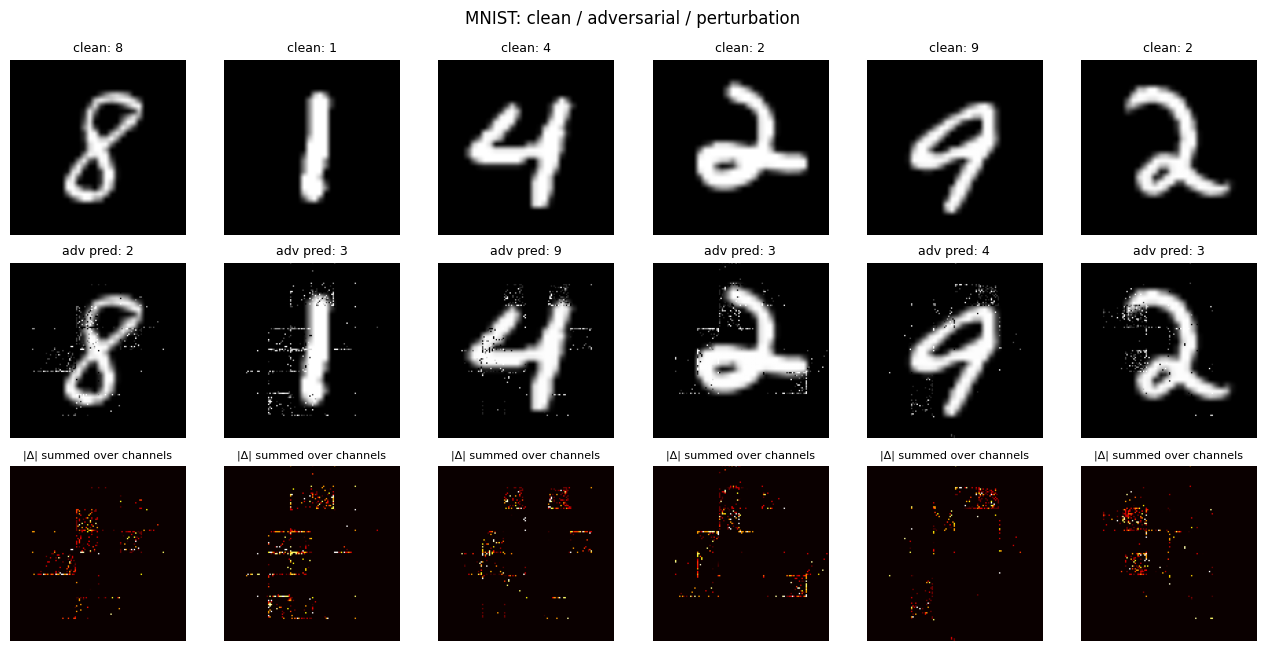

[MNIST] stage 'smooth' FAILED:
Traceback (most recent call last):
  File "/tmp/ipykernel_1304/829081452.py", line 3, in safe
    try: return fn(S)
                ~~^^^
  File "/tmp/ipykernel_1304/2883878877.py", line 46, in analysis_smooth
    flipped = pa != y; m = perturbation_metrics(x, xa)
                           ~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/tmp/ipykernel_1304/2883878877.py", line 21, in perturbation_metrics
    tv = torch.stack([total_variation(dd[None]) for dd in d]).squeeze(1)
IndexError: Dimension out of range (expected to be in range of [-1, 0], but got 1)

[MNIST] universal perturbation fooling rate on clean-correct test set: 0.902


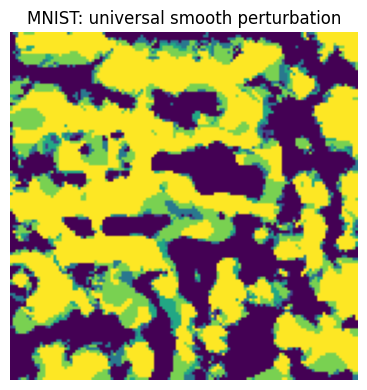

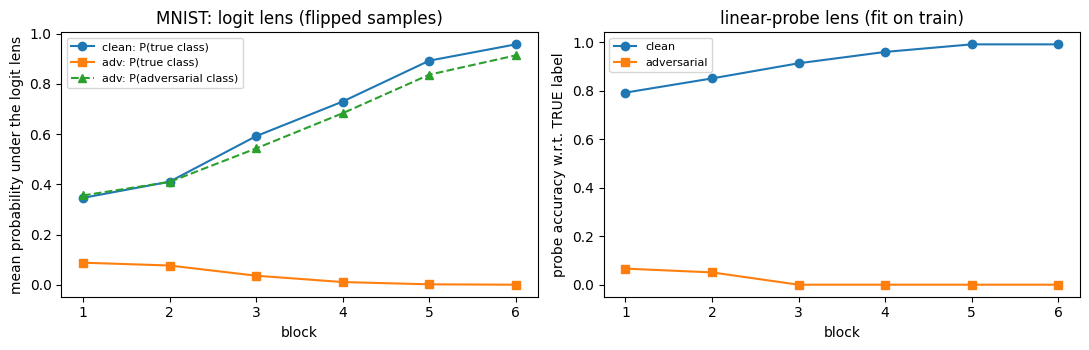

[MNIST] median commit layer (0-based): clean 1.0, adversarial 1.0 (of 6 blocks)


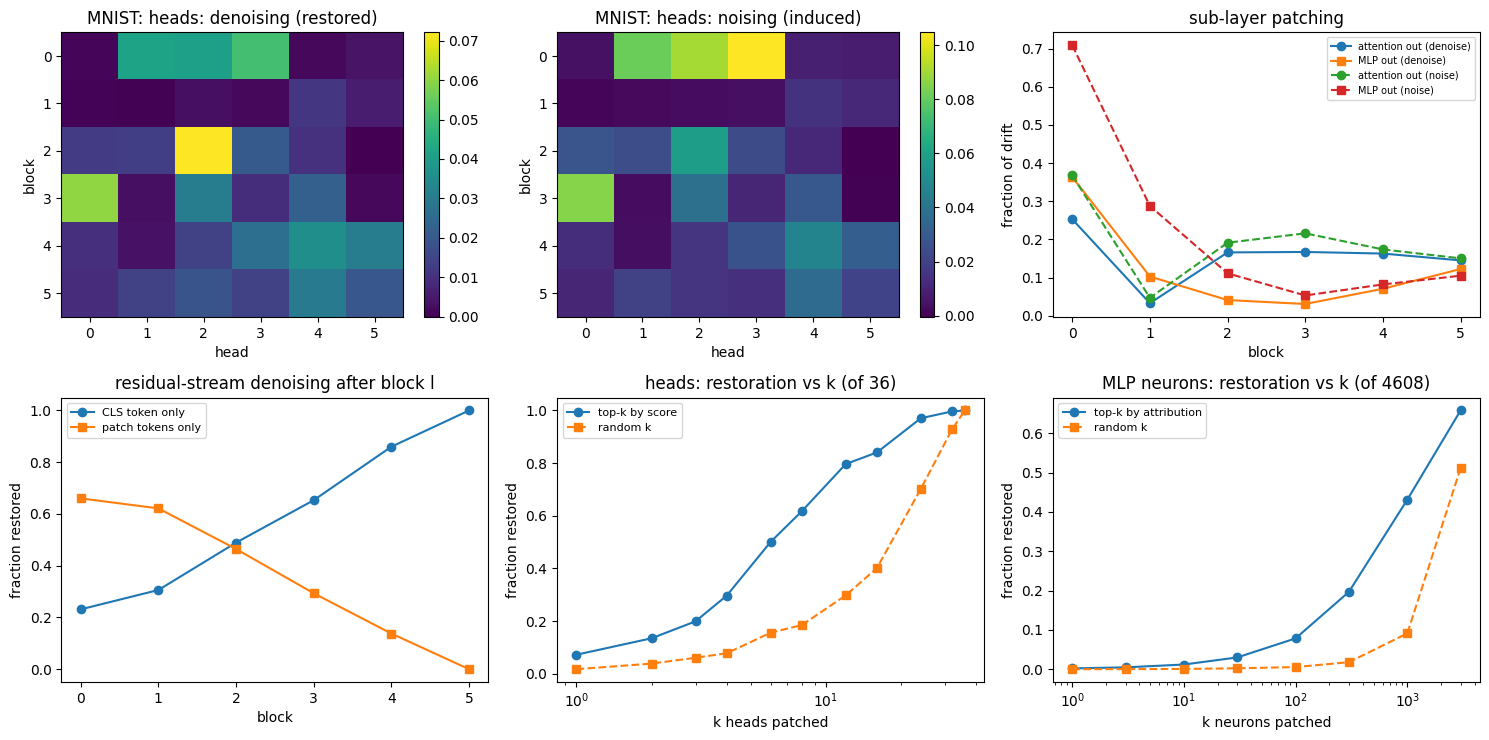

[MNIST] n=64 flipped samples | best single head (block, head)=(2, 2) restores 0.07 of the drift | k50 heads=6 of 36 | k50 neurons=3000 of 4608


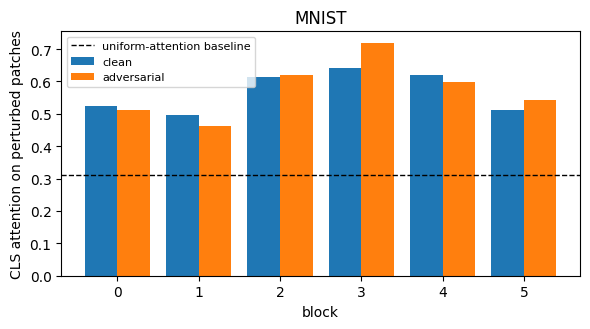

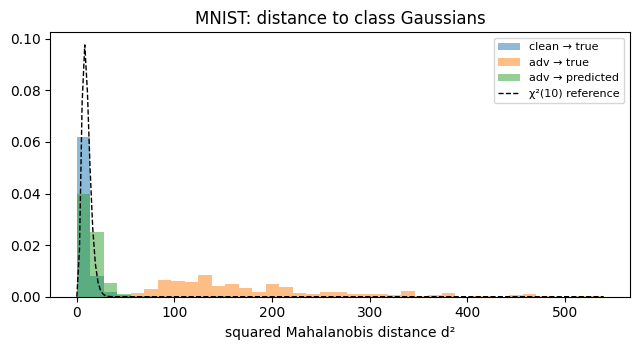

[MNIST] p<0.01 (χ² test): held-out clean 0.07 | clean→true 0.05 | adv→true 1.00 | adv→predicted 0.19 | adv closer to predicted class: 1.00
[MNIST] off-subspace energy of the attack: 0.838 (random baseline 0.952) | accuracy on adversarial images: 0.00 → 0.77 after projection (clean: 1.00) | on-subspace attack (19 native px) flip rate: 0.76
FashionMNIST


100%|██████████| 26.4M/26.4M [00:02<00:00, 11.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 171kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.29MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 5.60MB/s]


  epoch  1/15  train_loss=1.8600  test_acc=0.3535
  epoch  2/15  train_loss=1.4112  test_acc=0.4940
  epoch  3/15  train_loss=1.2007  test_acc=0.6220
  epoch  4/15  train_loss=1.0593  test_acc=0.5920
  epoch  5/15  train_loss=0.9760  test_acc=0.6675
  epoch  6/15  train_loss=0.8836  test_acc=0.7180
  epoch  7/15  train_loss=0.7884  test_acc=0.7005
  epoch  8/15  train_loss=0.7466  test_acc=0.7425
  epoch  9/15  train_loss=0.6899  test_acc=0.7740
  epoch 10/15  train_loss=0.6683  test_acc=0.7835
  epoch 11/15  train_loss=0.6125  test_acc=0.7805
  epoch 12/15  train_loss=0.5923  test_acc=0.7995
  epoch 13/15  train_loss=0.5739  test_acc=0.7960
  epoch 14/15  train_loss=0.5528  test_acc=0.7980
  epoch 15/15  train_loss=0.5498  test_acc=0.8015
[FashionMNIST] clean test accuracy: 0.8015   params: 2,733,514
[FashionMNIST] sanity checks passed (identity patching, logit lens at last block)
[FashionMNIST] budget 400 px (2.44%) | flipped 255/256 = 99.6% | changed pixels (mean) 303 | L2 8.55


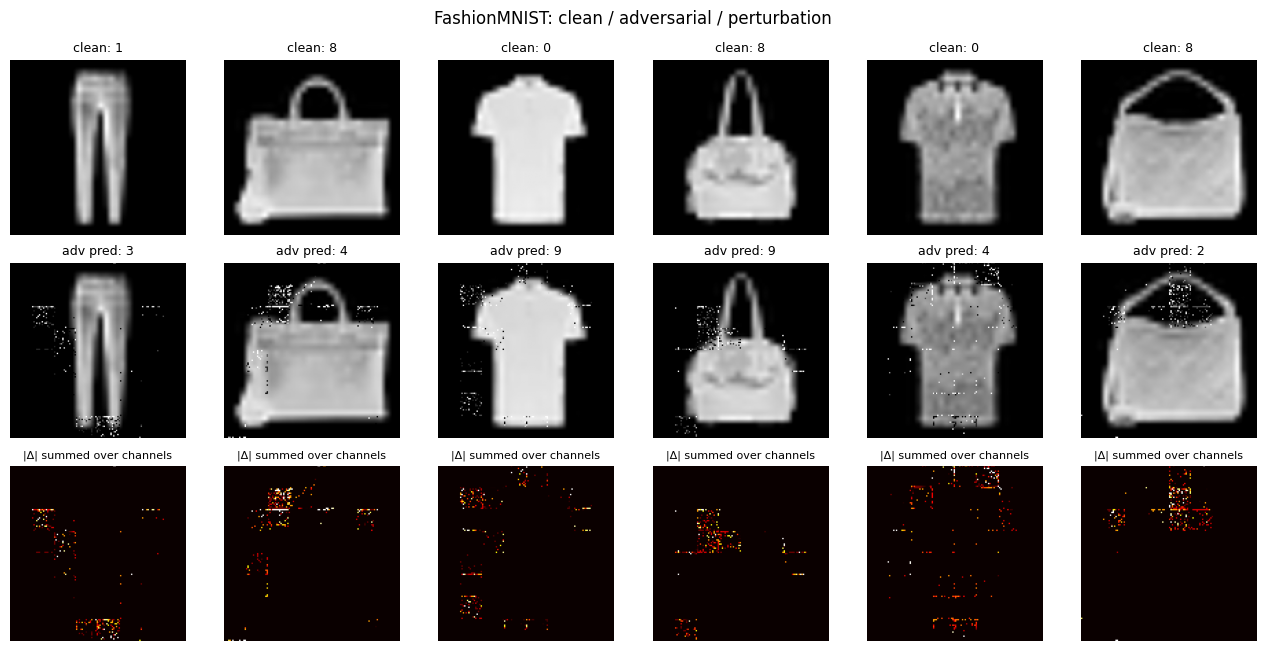

[FashionMNIST] stage 'smooth' FAILED:
Traceback (most recent call last):
  File "/tmp/ipykernel_1304/829081452.py", line 3, in safe
    try: return fn(S)
                ~~^^^
  File "/tmp/ipykernel_1304/2883878877.py", line 46, in analysis_smooth
    flipped = pa != y; m = perturbation_metrics(x, xa)
                           ~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/tmp/ipykernel_1304/2883878877.py", line 21, in perturbation_metrics
    tv = torch.stack([total_variation(dd[None]) for dd in d]).squeeze(1)
IndexError: Dimension out of range (expected to be in range of [-1, 0], but got 1)

[FashionMNIST] universal perturbation fooling rate on clean-correct test set: 0.820


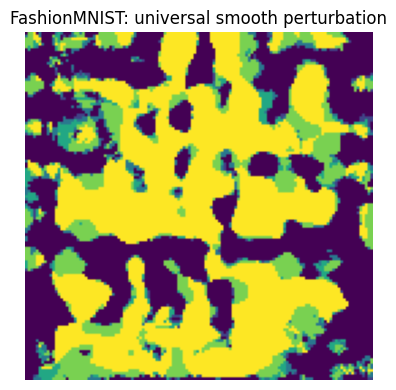

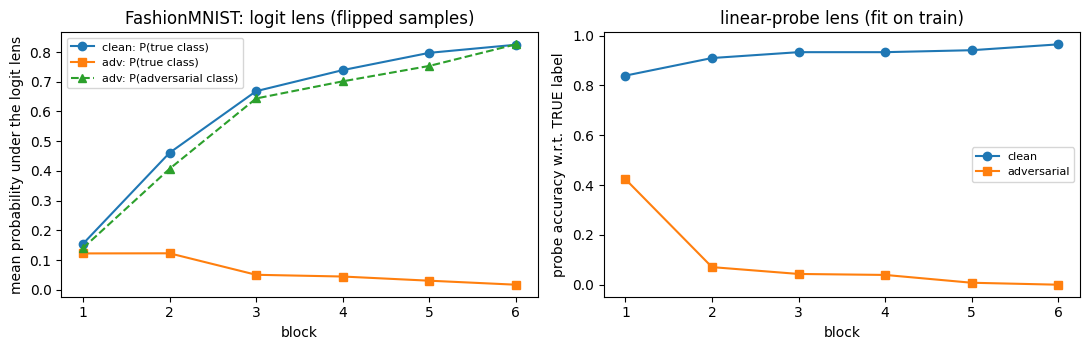

[FashionMNIST] median commit layer (0-based): clean 1.0, adversarial 1.0 (of 6 blocks)


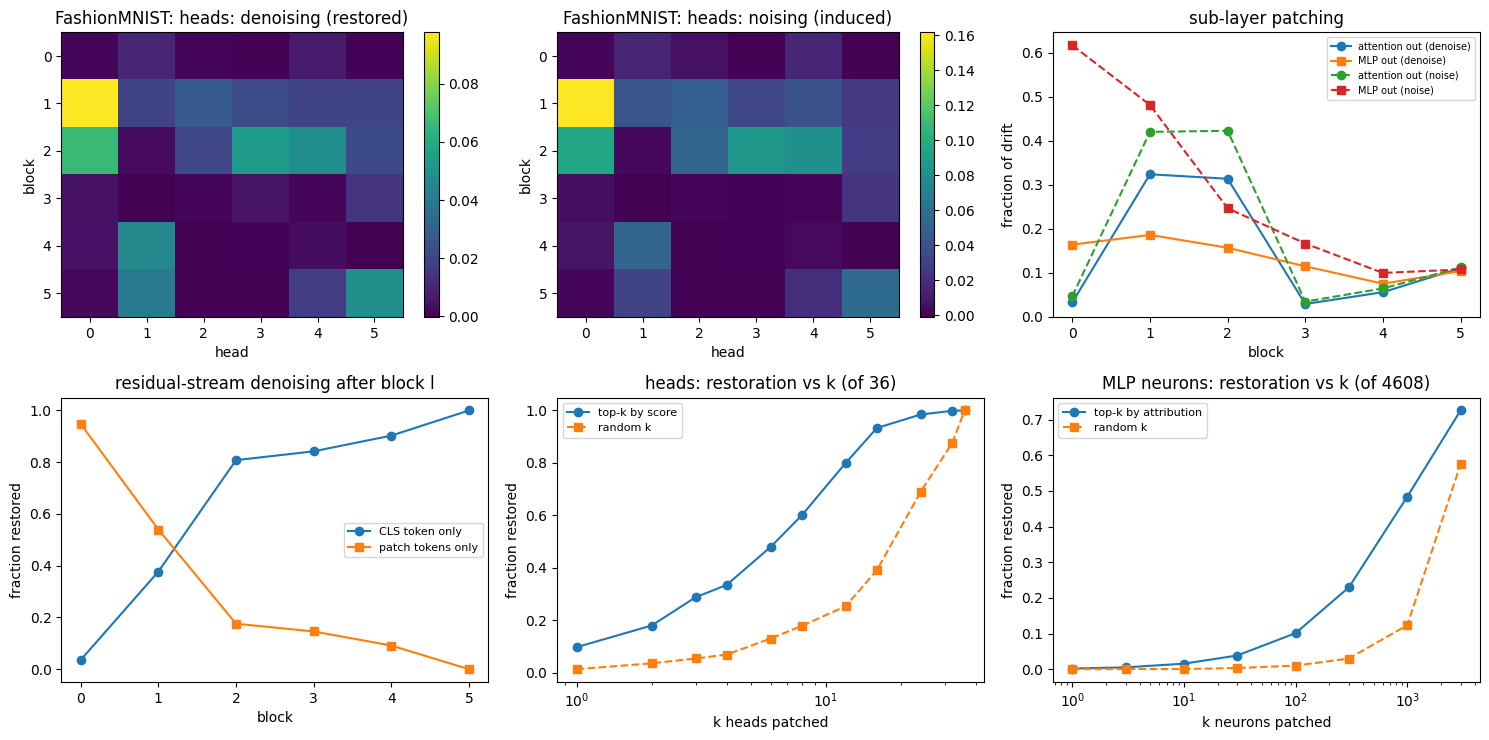

[FashionMNIST] n=64 flipped samples | best single head (block, head)=(1, 0) restores 0.10 of the drift | k50 heads=8 of 36 | k50 neurons=3000 of 4608


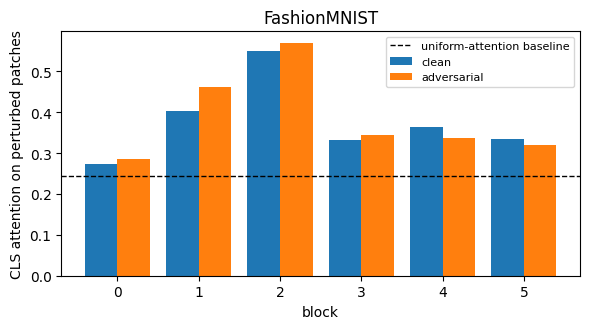

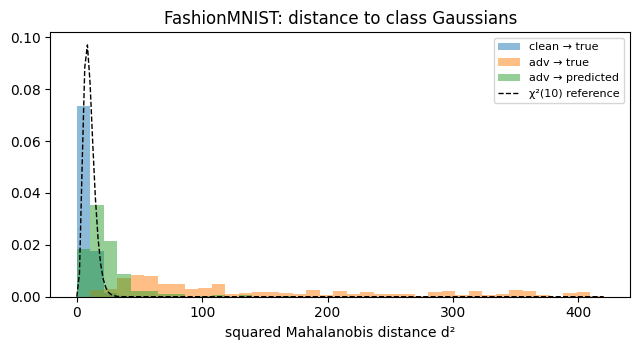

[FashionMNIST] p<0.01 (χ² test): held-out clean 0.07 | clean→true 0.02 | adv→true 0.96 | adv→predicted 0.37 | adv closer to predicted class: 1.00
[FashionMNIST] off-subspace energy of the attack: 0.857 (random baseline 0.952) | accuracy on adversarial images: 0.00 → 0.56 after projection (clean: 1.00) | on-subspace attack (19 native px) flip rate: 0.68
CIFAR10


100%|██████████| 170M/170M [36:35<00:00, 77.7kB/s]


  epoch  1/15  train_loss=2.0344  test_acc=0.2910
  epoch  2/15  train_loss=1.8457  test_acc=0.3510
  epoch  3/15  train_loss=1.7349  test_acc=0.3795
  epoch  4/15  train_loss=1.6426  test_acc=0.4275
  epoch  5/15  train_loss=1.5893  test_acc=0.4225
  epoch  6/15  train_loss=1.5085  test_acc=0.4615
  epoch  7/15  train_loss=1.4581  test_acc=0.4845
  epoch  8/15  train_loss=1.4040  test_acc=0.5110
  epoch  9/15  train_loss=1.3434  test_acc=0.5065
  epoch 10/15  train_loss=1.2925  test_acc=0.5245
  epoch 11/15  train_loss=1.2287  test_acc=0.5275
  epoch 12/15  train_loss=1.2061  test_acc=0.5345
  epoch 13/15  train_loss=1.1685  test_acc=0.5465
  epoch 14/15  train_loss=1.1453  test_acc=0.5525
  epoch 15/15  train_loss=1.1309  test_acc=0.5540
[CIFAR10] clean test accuracy: 0.5540   params: 2,831,818
[CIFAR10] sanity checks passed (identity patching, logit lens at last block)
[CIFAR10] budget 400 px (2.44%) | flipped 254/256 = 99.2% | changed pixels (mean) 392 | L2 12.74


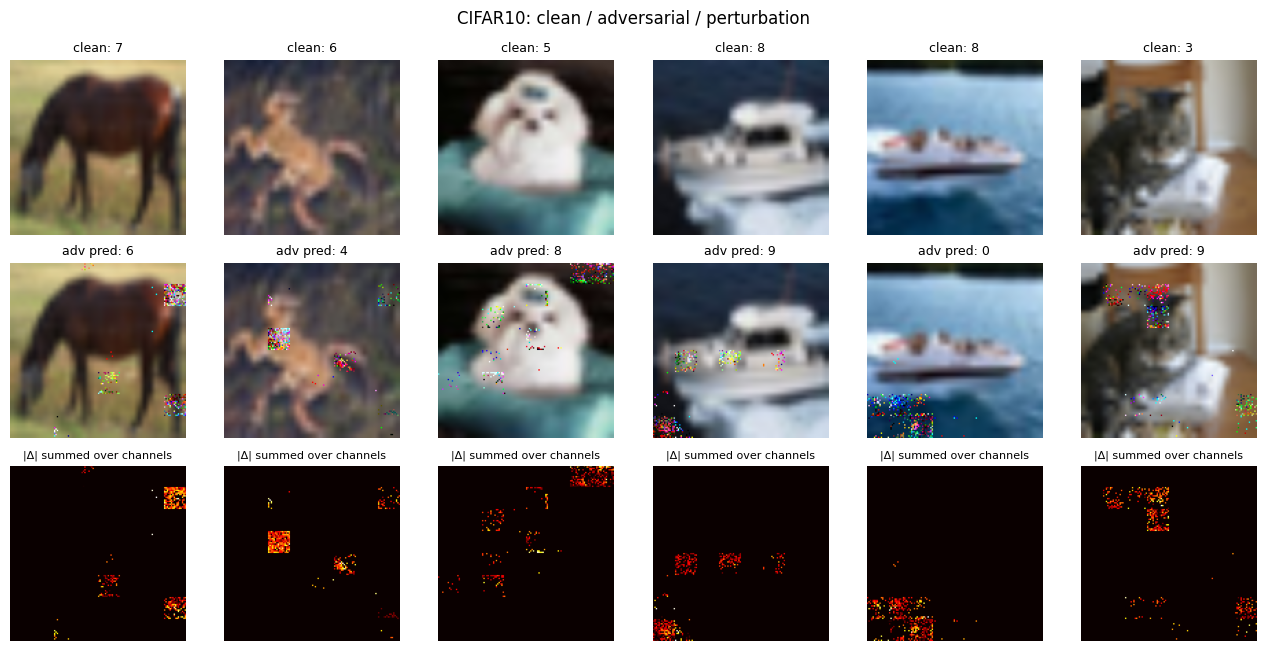

[CIFAR10] stage 'smooth' FAILED:
Traceback (most recent call last):
  File "/tmp/ipykernel_1304/829081452.py", line 3, in safe
    try: return fn(S)
                ~~^^^
  File "/tmp/ipykernel_1304/2883878877.py", line 46, in analysis_smooth
    flipped = pa != y; m = perturbation_metrics(x, xa)
                           ~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/tmp/ipykernel_1304/2883878877.py", line 21, in perturbation_metrics
    tv = torch.stack([total_variation(dd[None]) for dd in d]).squeeze(1)
IndexError: Dimension out of range (expected to be in range of [-1, 0], but got 1)

[CIFAR10] universal perturbation fooling rate on clean-correct test set: 0.840


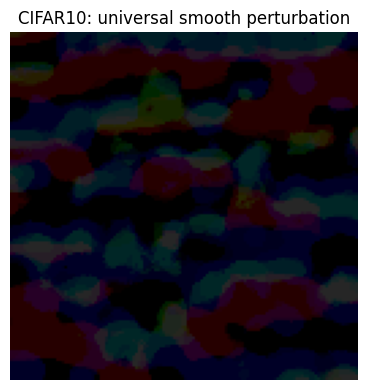

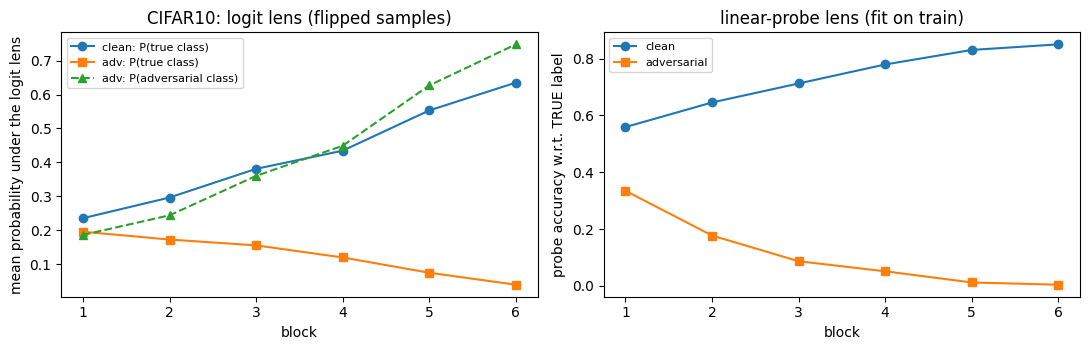

[CIFAR10] median commit layer (0-based): clean 2.0, adversarial 2.0 (of 6 blocks)


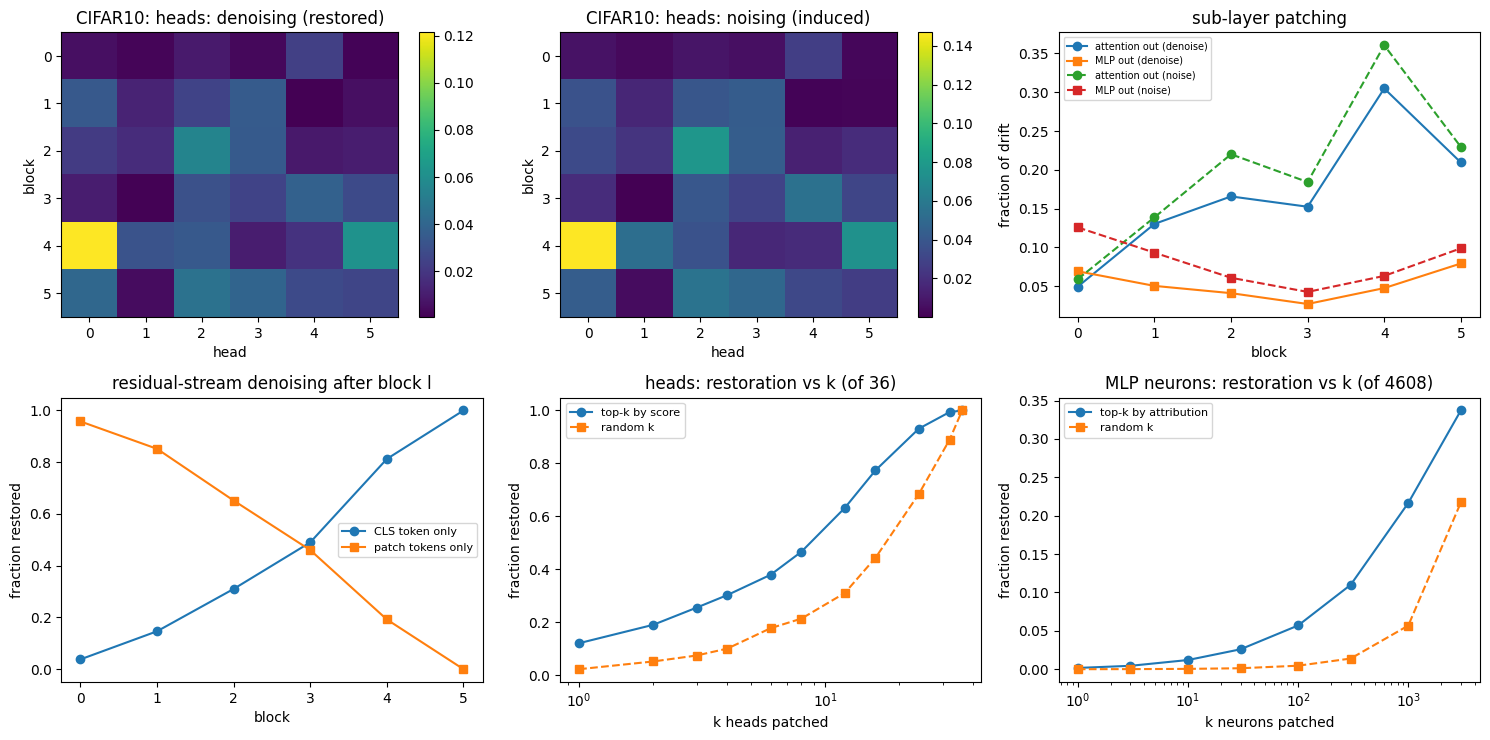

[CIFAR10] n=64 flipped samples | best single head (block, head)=(4, 0) restores 0.12 of the drift | k50 heads=12 of 36 | k50 neurons=nan of 4608


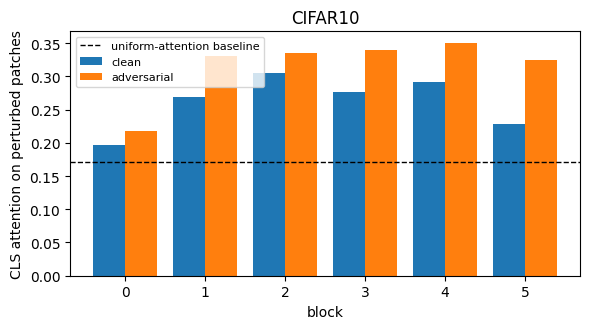

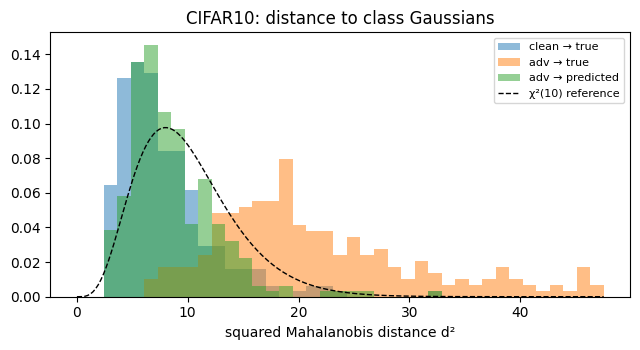

[CIFAR10] p<0.01 (χ² test): held-out clean 0.06 | clean→true 0.00 | adv→true 0.38 | adv→predicted 0.02 | adv closer to predicted class: 0.99
[CIFAR10] off-subspace energy of the attack: 0.756 (random baseline 0.938) | accuracy on adversarial images: 0.01 → 0.09 after projection (clean: 1.00) | on-subspace attack (25 native px) flip rate: 0.90
SVHN


100%|██████████| 182M/182M [00:35<00:00, 5.09MB/s]
100%|██████████| 64.3M/64.3M [00:22<00:00, 2.83MB/s]


  epoch  1/15  train_loss=2.2547  test_acc=0.1965
  epoch  2/15  train_loss=2.2115  test_acc=0.1970
  epoch  3/15  train_loss=2.1631  test_acc=0.2805
  epoch  4/15  train_loss=2.0689  test_acc=0.3105
  epoch  5/15  train_loss=1.9304  test_acc=0.3690
  epoch  6/15  train_loss=1.7470  test_acc=0.4025
  epoch  7/15  train_loss=1.6407  test_acc=0.4770
  epoch  8/15  train_loss=1.5215  test_acc=0.4880
  epoch  9/15  train_loss=1.4567  test_acc=0.5160
  epoch 10/15  train_loss=1.3902  test_acc=0.5295
  epoch 11/15  train_loss=1.2994  test_acc=0.5700
  epoch 12/15  train_loss=1.2513  test_acc=0.5835
  epoch 13/15  train_loss=1.2163  test_acc=0.6000
  epoch 14/15  train_loss=1.1793  test_acc=0.6050
  epoch 15/15  train_loss=1.1819  test_acc=0.6050
[SVHN] clean test accuracy: 0.6050   params: 2,831,818
[SVHN] sanity checks passed (identity patching, logit lens at last block)
[SVHN] budget 400 px (2.44%) | flipped 256/256 = 100.0% | changed pixels (mean) 390 | L2 12.56


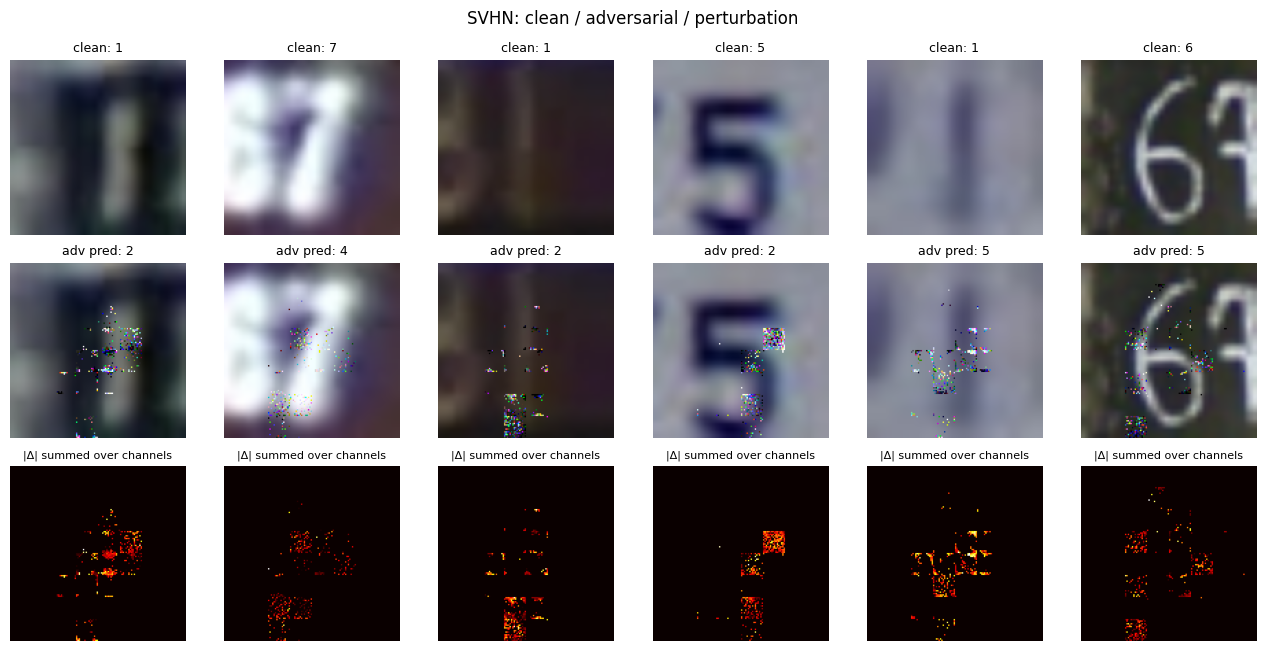

[SVHN] stage 'smooth' FAILED:
Traceback (most recent call last):
  File "/tmp/ipykernel_1304/829081452.py", line 3, in safe
    try: return fn(S)
                ~~^^^
  File "/tmp/ipykernel_1304/2883878877.py", line 46, in analysis_smooth
    flipped = pa != y; m = perturbation_metrics(x, xa)
                           ~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/tmp/ipykernel_1304/2883878877.py", line 21, in perturbation_metrics
    tv = torch.stack([total_variation(dd[None]) for dd in d]).squeeze(1)
IndexError: Dimension out of range (expected to be in range of [-1, 0], but got 1)

[SVHN] universal perturbation fooling rate on clean-correct test set: 0.934


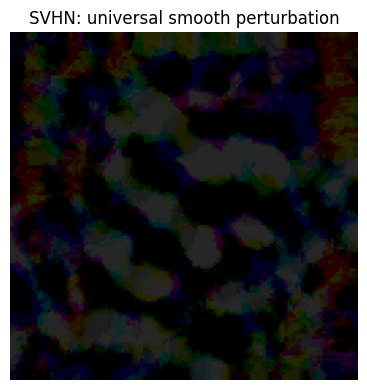

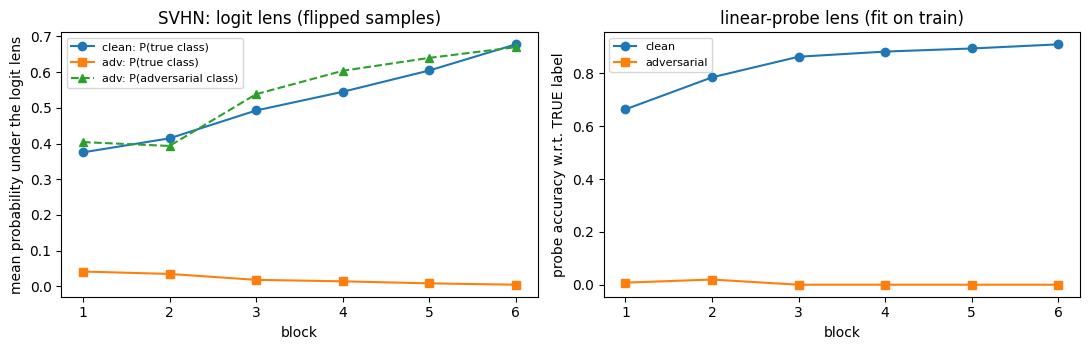

[SVHN] median commit layer (0-based): clean 1.0, adversarial 0.0 (of 6 blocks)


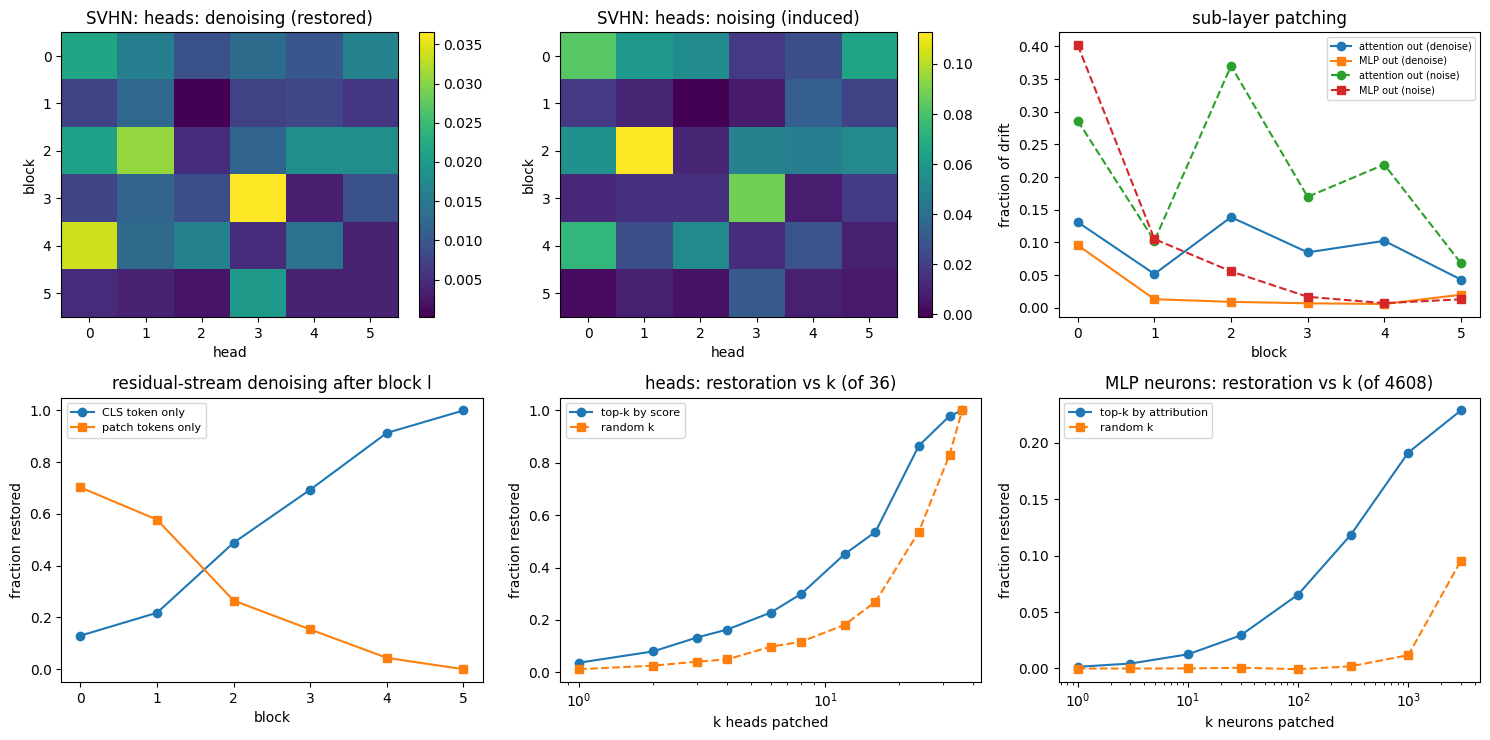

[SVHN] n=64 flipped samples | best single head (block, head)=(3, 3) restores 0.04 of the drift | k50 heads=16 of 36 | k50 neurons=nan of 4608


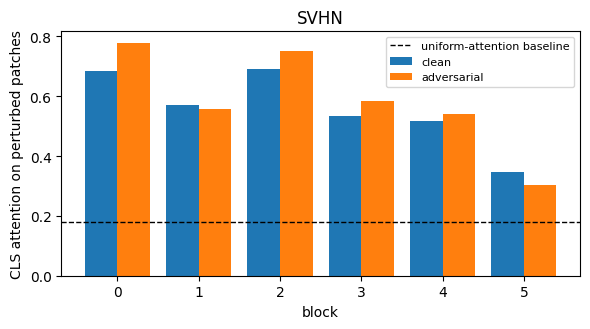

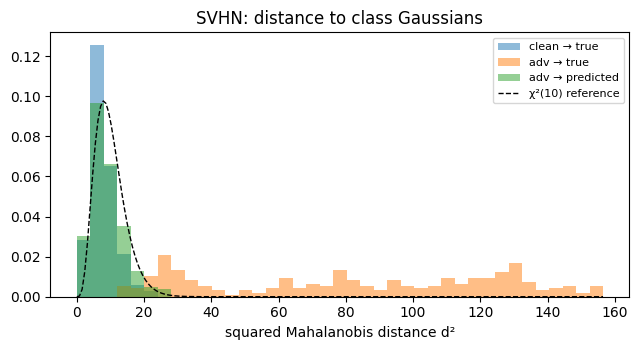

[SVHN] p<0.01 (χ² test): held-out clean 0.06 | clean→true 0.00 | adv→true 0.94 | adv→predicted 0.02 | adv closer to predicted class: 1.00
[SVHN] off-subspace energy of the attack: 0.802 (random baseline 0.938) | accuracy on adversarial images: 0.00 → 0.04 after projection (clean: 1.00) | on-subspace attack (25 native px) flip rate: 0.99


In [17]:
RESULTS, ERRORS = {}, {}
def safe(tag, fn, S):
    try: return fn(S)
    except Exception:
        ERRORS[(S["name"], tag)] = traceback.format_exc(); print(f"[{S['name']}] stage '{tag}' FAILED:\n{ERRORS[(S['name'], tag)]}"); return {}

for name in CFG["DATASETS"]:
    print("=" * 100, f"\n{name}\n" + "=" * 100)
    seed_all(CFG["SEED"])
    S = setup_dataset(name); prepare_eval_set(S)
    if len(S["y"]) < 8: print(f"[{name}] too few correctly-classified images; skipping"); continue
    sanity_checks(S)
    R = dict(dataset=name, clean_acc=S["clean_acc"], n_attacked=len(S["y"]))
    R["attack"] = safe("attack", analysis_attack, S)
    R["smooth"] = safe("smooth", analysis_smooth, S)
    R["transfer"] = safe("transfer", analysis_transfer, S)
    R["imagenet"] = safe("imagenet", analysis_imagenet_pretrained, S)
    R["universal"] = safe("universal", analysis_universal, S)
    if R["attack"]:
        R["lens"] = safe("lens", analysis_lens, S); R["patch"] = safe("patch", analysis_patch, S)
        R["attention"] = safe("attention", analysis_attention, S); R["manifold"] = safe("manifold", analysis_manifold, S)
        R["subspace"] = safe("subspace", analysis_subspace, S)
    RESULTS[name] = R
    del S; torch.cuda.empty_cache()

## 17. Cross-dataset summary

In [18]:
def g(d, *ks, default=np.nan):
    for k in ks:
        if not isinstance(d, dict) or k not in d: return default
        d = d[k]
    return d

rows = []
for n, R in RESULTS.items():
    rows.append({"dataset": n, "clean_acc": R["clean_acc"], "n_attacked": R["n_attacked"],
                 "flip_rate": g(R, "attack", "flip_rate"), "mean_L0_px": g(R, "attack", "mean_L0"), "mean_L2": g(R, "attack", "mean_L2"),
                 "smooth_flip_rate": g(R, "smooth", "flip_rate"), "smooth_psnr": g(R, "smooth", "psnr"),
                 "smooth_tv": g(R, "smooth", "tv"), "transfer_flip_rate": g(R, "transfer", "transfer_flip_rate"),
                 "universal_fooling_rate": g(R, "universal", "universal_fooling_rate"),
                 "imagenet_prediction_change": g(R, "imagenet", "imagenet_prediction_change"),
                 "lens_commit_clean": g(R, "lens", "commit_clean"), "lens_commit_adv": g(R, "lens", "commit_adv"),
                 "best_head": str(g(R, "patch", "top_head", default="")), "best_head_restored": g(R, "patch", "top_head_score"),
                 "k50_heads": g(R, "patch", "k50_heads"), "of_heads": g(R, "patch", "n_heads"),
                 "k50_neurons": g(R, "patch", "k50_neurons"), "of_neurons": g(R, "patch", "n_neurons"),
                 "attn_gain_on_perturbed": g(R, "attention", "mean_gain"),
                 "adv_p<0.01_true": g(R, "manifold", "frac_p01_adv_true"), "clean_p<0.01_heldout": g(R, "manifold", "frac_p01_heldout_clean"),
                 "rho_perp": g(R, "subspace", "rho_perp_mean"), "rho_perp_random": g(R, "subspace", "rho_perp_random_baseline"),
                 "acc_after_projection": g(R, "subspace", "acc_after_projection"), "flip_rate_on_subspace": g(R, "subspace", "flip_rate_native_attack")})
SUMMARY = pd.DataFrame(rows).set_index("dataset")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50)
display(SUMMARY.round(3))
SUMMARY.round(4).to_csv(os.path.join(CFG["OUT_DIR"], "summary.csv"))

def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
with open(os.path.join(CFG["OUT_DIR"], "results.json"), "w") as fh: json.dump(_clean(RESULTS), fh, indent=1)
if ERRORS: print("stages that failed:", list(ERRORS))

,clean_acc,n_attacked,flip_rate,mean_L0_px,mean_L2,smooth_flip_rate,smooth_psnr,smooth_tv,transfer_flip_rate,universal_fooling_rate,imagenet_prediction_change,lens_commit_clean,lens_commit_adv,best_head,best_head_restored,k50_heads,of_heads,k50_neurons,of_neurons,attn_gain_on_perturbed,adv_p<0.01_true,clean_p<0.01_heldout,rho_perp,rho_perp_random,acc_after_projection,flip_rate_on_subspace
dataset,,,,,,,,,,,,,,,,,,,,,,,,,,
MNIST,0.961,256,1.000,299.395,8.887,NaN,NaN,NaN,NaN,0.902,NaN,1.0,1.0,"(2, 2)",0.072,6,36,3000.0,4608,0.007,1.000,0.073,0.838,0.952,0.766,0.762
FashionMNIST,0.802,256,0.996,302.879,8.553,NaN,NaN,NaN,NaN,0.820,NaN,1.0,1.0,"(1, 0)",0.098,8,36,3000.0,4608,0.010,0.965,0.065,0.857,0.952,0.559,0.684
CIFAR10,0.554,256,0.992,392.234,12.739,NaN,NaN,NaN,NaN,0.840,NaN,2.0,2.0,"(4, 0)",0.121,12,36,NaN,4608,0.056,0.382,0.059,0.756,0.938,0.094,0.898
SVHN,0.605,256,1.000,390.422,12.559,NaN,NaN,NaN,NaN,0.934,NaN,1.0,0.0,"(3, 3)",0.037,16,36,NaN,4608,0.028,0.938,0.063,0.802,0.938,0.039,0.988


stages that failed: [('MNIST', 'smooth'), ('FashionMNIST', 'smooth'), ('CIFAR10', 'smooth'), ('SVHN', 'smooth')]


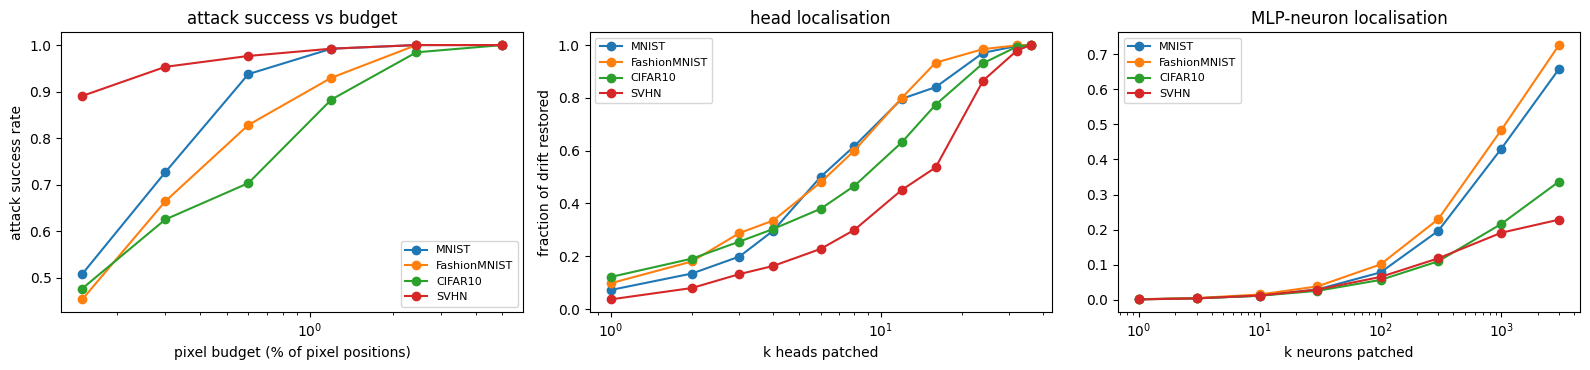

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for n, R in RESULTS.items():
    sw = g(R, "attack", "sweep", default={})
    if sw: ax[0].plot([100 * k for k in sw], list(sw.values()), "o-", label=n)
    p = g(R, "patch", default={})
    if p:
        ax[1].semilogx(p["ks_heads"], p["heads_curve"], "o-", label=n); ax[2].semilogx(p["ks_neurons"], p["neurons_curve"], "o-", label=n)
ax[0].set(xlabel="pixel budget (% of pixel positions)", ylabel="attack success rate", title="attack success vs budget"); ax[0].set_xscale("log")
ax[1].set(xlabel="k heads patched", ylabel="fraction of drift restored", title="head localisation"); ax[2].set(xlabel="k neurons patched", title="MLP-neuron localisation")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); savefig("ALL", "summary"); plt.show()

## 18. Reading the results, and where to take it next

**How to read them.** `flip_rate` at the fixed budget and the budget sweep say how brittle each model is; `lens_commit_*` says at which depth the prediction becomes stable; `k50_heads` / `k50_neurons` (vs `of_heads` / `of_neurons`) say how *localised* the drift is (small = a few components carry it, close to the full count = distributed); `rho_perp` vs `rho_perp_random` shows whether the attack concentrates energy off the data subspace, and `acc_after_projection` / `flip_rate_on_subspace` separate on- from off-subspace vulnerability. Every number comes from one trained model per dataset and a few hundred images: for claims, repeat over seeds and report intervals.

**Extensions** (all controlled from `CFG`):
* `IMG_SIZE` ∈ {64, 128, 256} (and `PATCH`) to study robustness as a function of ambient dimension at a fixed budget *fraction*.
* `PRETRAINED="vit_tiny_patch16_224"` / `"vit_small_patch16_224"` for pretrained initialisations; more data/epochs for CIFAR-like sets.
* `ATTACK_LOSS="ce"` to reproduce the CNN notebook's objective; larger `N_EVAL`/`N_PATCH` for tighter estimates.
* Add datasets by extending `NATIVE` and `load_dataset` (native size ≤ 32 keeps the exact-subspace analysis valid).
* Sparse autoencoders: `Recorder` can cache `resid`/`neuron` taps to train per-layer SAEs with `k ≪ d_in` (see the PDF companion for pitfalls).

## Download Results

In [20]:
import shutil
import os

output_dir = CFG["OUT_DIR"]
archive_name = os.path.join(output_dir, "all_results")

# Create a zip archive of the output directory, handling potentially large files
shutil.make_archive(archive_name, 'zip', output_dir, force_zip64=True)

print(f"All results and figures have been archived to: {archive_name}.zip")
print("You can download this file from the Colab file browser (left panel -> folder icon).")

TypeError: make_archive() got an unexpected keyword argument 'force_zip64'